<font size=20> <b> *Performance Analysis*  </font>

---

# **Process**

## **Portfolio 분석**

- **Portfolio Return 분석**
    - <u>**항목별(BPM 기준)**</u> 분석(PP vs. FP)
    - <u>**종목별**</u> 분석(PP vs. FP)
    - <u>**업종별**</u> 이익 기여도 추이
- **Portfolio Risk 분석**
    - <u>**항목별(BPM 기준)**</u> 분석(PP vs. FP)
    - <u>**종목별**</u> 분석(PP vs. FP)
- **Portfolio Exposure 분석**
    - <u>**종목 Expoosure**</u> 분석(PP vs. FP)
    - <u>**업종 Exposure**</u> 분석(PP vs. FP)
    - <u>**BPM Factor Exposure**</u> 분석(PP vs. FP)

## **Alpha 분석**

- **IC 분석**
    - TC 변화 체크(FP)
    - FMP 성과
    - IC 누적
    - Scatter Plot (Score vs. Foward Return)
    - IC Decay
- **분위 분석**
    - TMB Spread 분석
    - 분위별 Return
- **Score 분석**
    - Score Change Top/Bottom
    - Score Top/Bottom
- **Raw Data 분석**
    - Raw Data 추이
    - 특정일자 Raw Data
    - 종목 수익률 추이

## **Constraints 분석**

- **BPM Factor Return 분석**
- **BPM Sector Return 분석**

# **Setting**

## Import Package

In [1]:
import jackhammer as jh
from jackhammer import optimizer as opt
import jackhammer.hubble as hb

import vrksa as vr
import vrksa.computations as vc
import vrksa.datasets_kr as vdk
import vrksa.historysets as vh

import pandas as pd
import numpy as np
import pickle
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import plotly.offline as po
from plotly.offline import init_notebook_mode, iplot
import plotly.graph_objs as go
import plotly.figure_factory as ff
from plotly.subplots import make_subplots
import plotly.express as px
import missingno as msno

from sklearn.decomposition import PCA
from sklearn import linear_model

import scipy
from scipy import stats
from scipy.stats import zscore

import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import sqlalchemy
from sqlalchemy import create_engine

import copy

import datetime
import time
import os

import pyfolio as pf
import random

init_notebook_mode(connected=True)
idx = pd.IndexSlice

%matplotlib inline 
%reload_ext autoreload
%autoreload 2
%config Completer.use_jedi = False
sns.set()
mpl.rc('font', family='nanumgothic') # 그림 한글 폰트 지정
mpl.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_rows', 20)
plt.style.use('fivethirtyeight')

BM 정기변경 선반영 관련 (2024.12.23)
1. 당월 MP가 선반영된 BM으로 산출되었을 경우, `bm_pre_rebal`=`True` 설정 (False 설정시 지수 변경 중복 반영)
2. 즉 <12월 MP 반영일 ~ 1월 MP 반영일> 사이 기간은 `bm_pre_rebal`=`True` 설정 필요

In [2]:
# Calculate Return Contribution
mp_start_date = '2023-02-13' # 데이터를 저장할 첫 영업일(최초 MP 시작일인 2023-02-13 이후로 입력 필 // WTD면 전주 마지막 영업일, MTD면 전월 마지막 영업일)
report_start_date = '2026-08-28' # 아래 성과 기여도 부분에서 보여질 기간의 첫 영업일(주간의 경우 전주 마지막 영업일, 월간의 경우 전월 마지막 영업일)
mp_end_date = '2026-09-04'
analysis_bm = 'kospi200' # 'kospi','kospi200'
data_load = True # 처음 한번만 True

bm_pre_rebal = False
if bm_pre_rebal:
    rebal_end_dt = '2026-06-08' # 마지막 리벨런싱일자(bm변경내역 반영할 mp 일자)
    bm_reb_date = '2026-06-12' # BM변경 반영일(effective date)

%run 'Function_calculation_return_contribution_ver2.ipynb'

[Timestamp('2023-02-13 00:00:00+0000', tz='UTC'), Timestamp('2023-03-14 00:00:00+0000', tz='UTC'), Timestamp('2023-04-11 00:00:00+0000', tz='UTC'), Timestamp('2023-05-15 00:00:00+0000', tz='UTC'), Timestamp('2023-06-02 00:00:00+0000', tz='UTC'), Timestamp('2023-07-10 00:00:00+0000', tz='UTC'), Timestamp('2023-08-08 00:00:00+0000', tz='UTC'), Timestamp('2023-09-11 00:00:00+0000', tz='UTC'), Timestamp('2023-10-13 00:00:00+0000', tz='UTC'), Timestamp('2023-11-13 00:00:00+0000', tz='UTC'), Timestamp('2023-12-08 00:00:00+0000', tz='UTC'), Timestamp('2024-01-08 00:00:00+0000', tz='UTC'), Timestamp('2024-02-19 00:00:00+0000', tz='UTC'), Timestamp('2024-03-08 00:00:00+0000', tz='UTC'), Timestamp('2024-04-12 00:00:00+0000', tz='UTC'), Timestamp('2024-05-13 00:00:00+0000', tz='UTC'), Timestamp('2024-06-07 00:00:00+0000', tz='UTC'), Timestamp('2024-07-05 00:00:00+0000', tz='UTC'), Timestamp('2024-08-13 00:00:00+0000', tz='UTC'), Timestamp('2024-09-09 00:00:00+0000', tz='UTC'), Timestamp('2024-10-

  0%            (DATE) 0/869 |                     Elapsed 00:00 | Remaining ? | ?s/it

// Testing is completed.

◎ Event Log
 ╭────────┬──────────────────────┬────────────┬────────────────────────────────╮
 │      1 │ Rebalancing          │ 2023-02-13 │ 200 trades                     │
 │      2 │                      │ 2023-03-14 │ 200 trades                     │
 │    ··· │                      │   ·····    │ ·····                          │
 │     42 │                      │ 2026-07-08 │ 200 trades                     │
 │     43 │                      │ 2026-08-10 │ 200 trades                     │
 ├────────┼──────────────────────┼────────────┼────────────────────────────────┤
 │      1 │ No price data        │ 2023-04-25 │ A008560 : cash out             │
 │      2 │                      │ 2024-07-09 │ A003410 : cash out             │
 │      3 │                      │ 2025-12-15 │ A010620 : cash out             │
 │      4 │                      │ 2026-01-26 │ A042670 : cash out             │
 │      5 │                      │ 2026-07-20 │ A057050 : cash out     

  0%            (DATE) 0/869 |                     Elapsed 00:00 | Remaining ? | ?s/it

// Testing is completed.

◎ Event Log
 ╭────────┬──────────────────────┬────────────┬────────────────────────────────╮
 │      1 │ Rebalancing          │ 2023-02-13 │ 200 trades                     │
 │      2 │                      │ 2023-03-14 │ 200 trades                     │
 │    ··· │                      │   ·····    │ ·····                          │
 │     42 │                      │ 2026-07-08 │ 200 trades                     │
 │     43 │                      │ 2026-08-10 │ 200 trades                     │
 ├────────┼──────────────────────┼────────────┼────────────────────────────────┤
 │      1 │ No price data        │ 2023-04-25 │ A008560 : cash out             │
 │      2 │                      │ 2024-07-09 │ A003410 : cash out             │
 │      3 │                      │ 2025-12-15 │ A010620 : cash out             │
 │      4 │                      │ 2026-01-26 │ A042670 : cash out             │
 │      5 │                      │ 2026-07-20 │ A057050 : cash out     

...

// Testing is completed.

◎ Event Log
 ╭────────┬──────────────────────┬────────────┬────────────────────────────────╮
 │      1 │ Rebalancing          │ 2023-02-13 │ 200 trades                     │
 │      2 │                      │ 2023-03-14 │ 200 trades                     │
 │    ··· │                      │   ·····    │ ·····                          │
 │     42 │                      │ 2026-07-08 │ 200 trades                     │
 │     43 │                      │ 2026-08-10 │ 200 trades                     │
 ├────────┼──────────────────────┼────────────┼────────────────────────────────┤
 │      1 │ No price data        │ 2023-04-25 │ A008560 : cash out             │
 │      2 │                      │ 2024-07-09 │ A003410 : cash out             │
 │      3 │                      │ 2025-12-15 │ A010620 : cash out             │
 │      4 │                      │ 2026-01-26 │ A042670 : cash out             │
 │      5 │                      │ 2026-07-20 │ A057050 : cash out     

  0%            (DATE) 0/869 |                     Elapsed 00:00 | Remaining ? | ?s/it

// Testing is completed.

◎ Event Log
 ╭────────┬──────────────────────┬────────────┬────────────────────────────────╮
 │      1 │ Rebalancing          │ 2023-02-13 │ 200 trades                     │
 │      2 │                      │ 2023-03-14 │ 200 trades                     │
 │    ··· │                      │   ·····    │ ·····                          │
 │     42 │                      │ 2026-07-08 │ 200 trades                     │
 │     43 │                      │ 2026-08-10 │ 200 trades                     │
 ├────────┼──────────────────────┼────────────┼────────────────────────────────┤
 │      1 │ No price data        │ 2023-04-25 │ A008560 : cash out             │
 │      2 │                      │ 2024-07-09 │ A003410 : cash out             │
 │      3 │                      │ 2025-12-15 │ A010620 : cash out             │
 │      4 │                      │ 2026-01-26 │ A042670 : cash out             │
 │      5 │                      │ 2026-07-20 │ A057050 : cash out     

  0%            (DATE) 0/869 |                     Elapsed 00:00 | Remaining ? | ?s/it

// Testing is completed.

◎ Event Log
 ╭────────┬──────────────────────┬────────────┬────────────────────────────────╮
 │      1 │ Rebalancing          │ 2023-02-13 │ 200 trades                     │
 │      2 │                      │ 2023-03-14 │ 200 trades                     │
 │    ··· │                      │   ·····    │ ·····                          │
 │     42 │                      │ 2026-07-08 │ 200 trades                     │
 │     43 │                      │ 2026-08-10 │ 200 trades                     │
 ├────────┼──────────────────────┼────────────┼────────────────────────────────┤
 │      1 │ No price data        │ 2023-04-25 │ A008560 : cash out             │
 │      2 │                      │ 2024-07-09 │ A003410 : cash out             │
 │      3 │                      │ 2025-12-15 │ A010620 : cash out             │
 │      4 │                      │ 2026-01-26 │ A042670 : cash out             │
 │      5 │                      │ 2026-07-20 │ A057050 : cash out     

In [3]:
# Alpha Factor
date_score_start = '2022-12-29'
# date_score_start = '2020-01-02'
data_load = True # 처음 한번만 True

%run 'Function_get_score_ver1.ipynb'

# %run 'Function_Alphalense_ver1.ipynb'

## Alpha Score List
# fcm_descriptor_list = list_fcm_descriptor
# fcm_score_list = ['cluster_'+str(i) for i in cluster_list]+['composite']
# quality_descriptor_list = list_quality_descriptor 
# quality_score_list = list_quality_factor
# bpm_score_list = list_bpm_factor
# ia_score_list = ['investor_activity_score']

In [4]:
dates_q = '''SELECT  "date"           AS TD
                , (SELECT  MAX("date") FROM AQUANT.dbo.WORKDATE_MAST_TB WHERE "date" < '''+"'"+mp_end_date.replace('-','')+"'"+''' AND "W_E" = '1' AND "SYSTEM_GUBUN" = 'T')
                                    AS WTD
                , (SELECT  MAX("date") FROM AQUANT.dbo.WORKDATE_MAST_TB WHERE "date" < '''+"'"+mp_end_date.replace('-','')+"'"+''' AND "M_E" = '1' AND "SYSTEM_GUBUN" = 'T')
                                    AS MTD
                , (SELECT MAX("date")  FROM AQUANT.dbo.WORKDATE_MAST_TB WHERE "date" <= '''+"'"+mp_end_date.replace('-','')+"'"+''' AND "M_E" = '1' AND "SYSTEM_GUBUN" = 'T' AND SUBSTRING("date", 5, 2) IN ('03', '06', '09', '12')) 
                                    AS QTD
                , (SELECT MAX("date")  FROM AQUANT.dbo.WORKDATE_MAST_TB WHERE "date" <= '''+"'"+mp_end_date.replace('-','')+"'"+''' AND "M_E" = '1' AND "SYSTEM_GUBUN" = 'T' AND SUBSTRING("date", 5, 2) IN ( '06', '12')) 
                                    AS HTD
                , (SELECT  MAX("date") FROM AQUANT.dbo.WORKDATE_MAST_TB WHERE "date" < '''+"'"+mp_end_date.replace('-','')+"'"+''' AND "Y_E" = '1' AND "SYSTEM_GUBUN" = 'T')
                                    AS YTD
                                    ,  "DATE_1y_ago"    AS '1y_ago'

             FROM  AQUANT.dbo.WORKDATE_MAST_TB

            WHERE "date"         = '''+"'"+mp_end_date.replace('-','')+"'"+'''
              AND "SYSTEM_GUBUN" = 'T'

           ORDER BY 1 DESC'''

In [5]:
date_list = pd.read_sql(dates_q, conn, columns=True)

In [6]:
mtd_date = date_list['MTD'][0]
qtd_date = date_list['QTD'][0]
htd_date = date_list['HTD'][0]
ytd_date = date_list['YTD'][0]
y1_date = date_list['1y_ago'][0]

## **A. Return Contribution**

### 성과 기여도

,Hanwha_Quant_KS2_MP,RP
total,-1.15%,-1.21%
bm,-1.33%,-1.33%
active,0.18%,0.12%
market_timing,0.00%,0.00%
specific,0.06%,0.03%
risk_factor,0.12%,0.10%
industry_factor,-0.01%,-0.01%
country,-0.00%,-0.00%
selection,0.15%,0.12%
allocation,0.03%,0.00%


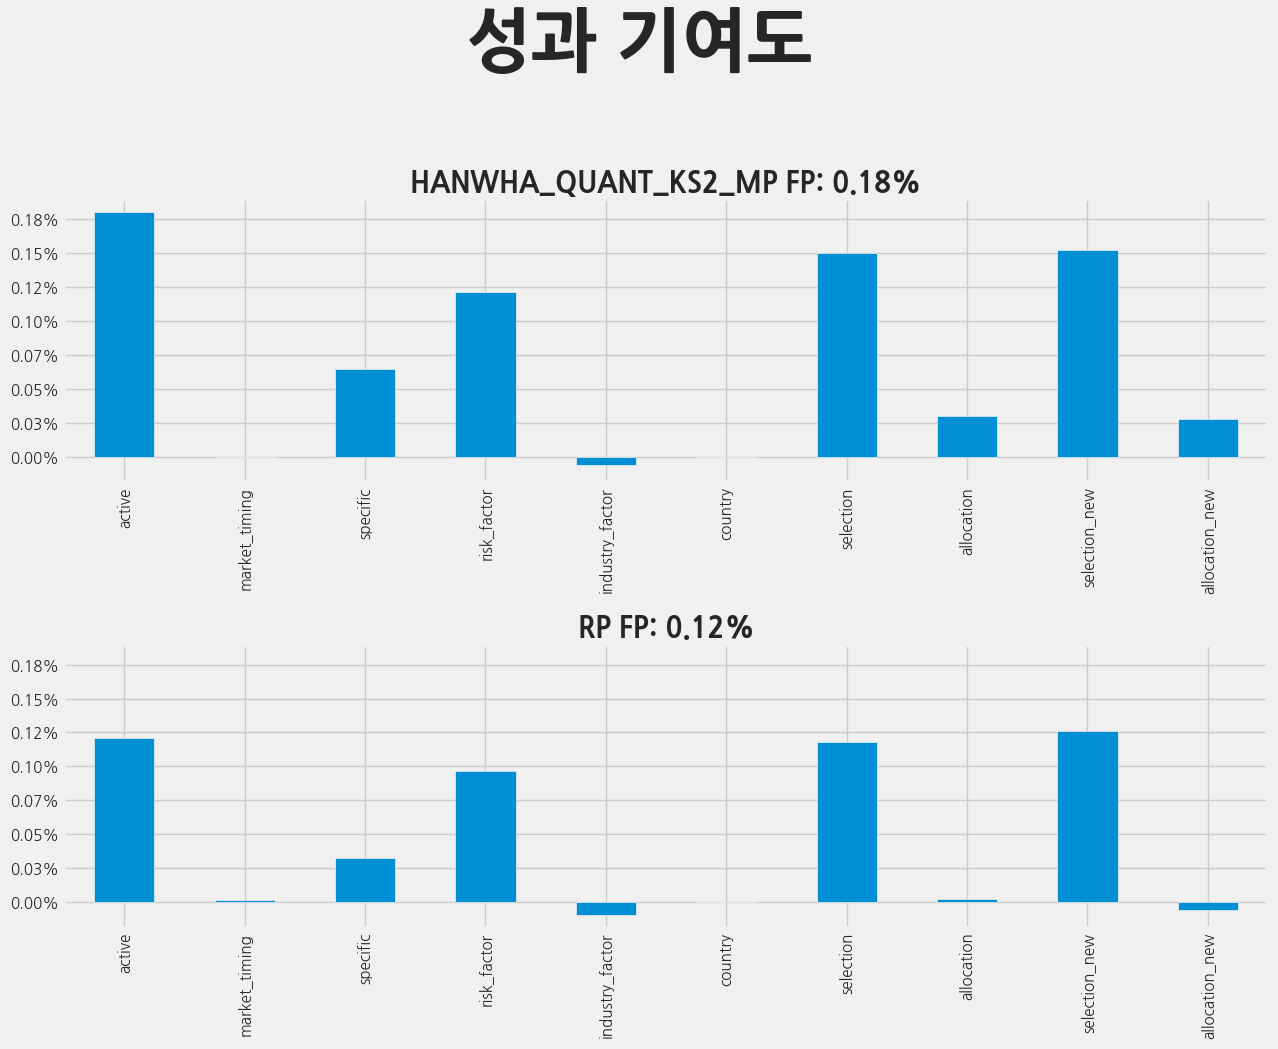

In [7]:
# 성과 기여도
fig, ax = plt.subplots(2, 1, figsize=(13,10), sharey=True)
ax = ax.ravel()
plot_colums_list = ['active','market_timing','specific','risk_factor','industry_factor','country','selection','allocation','selection_new','allocation_new']
for idxx, col in enumerate(return_contribution_final.columns.tolist()[-2:]):
    temp_plot = return_contribution_final[col][plot_colums_list].plot(kind='bar', ax=ax[idxx])
    ax[idxx].set_title(col.upper()+' FP: '+format(return_contribution_final[col].iloc[2],'.2%'), fontsize = 20, fontweight='bold')
    ax[idxx].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:.2%}"))
plt.suptitle('성과 기여도' , y=1.05, fontsize = 50, fontweight = "bold")  
plt.tight_layout()

return_contribution_final.iloc[:,-2:].style.format('{:.2%}') # return_contribution_raw.style.format('{:.4%}')

,KS2_CONSENSUS_FP,KS2_DIVIDEND_FP,KS2_INVESTMENT_FP,KS2_LTREV_FP,KS2_NEWIAM_FP,KS2_PRICEMOMENTUM_FP,KS2_PROFITABILITY_FP,KS2_PROFITABILITYGROWTH_FP,KS2_VALUE_FP,Hanwha_Quant_KS2_MP,RP
active,0.03%,0.07%,0.02%,0.12%,-0.10%,-0.01%,0.10%,0.06%,0.24%,0.18%,0.12%
market_timing,-0.01%,0.01%,0.01%,0.01%,-0.01%,-0.02%,0.01%,0.00%,0.01%,0.00%,0.00%
specific,0.05%,0.04%,-0.00%,0.04%,-0.07%,-0.03%,0.01%,0.01%,0.06%,0.06%,0.03%
risk_factor,-0.00%,0.03%,0.06%,0.07%,0.00%,0.00%,0.09%,0.06%,0.18%,0.12%,0.10%
industry_factor,-0.00%,-0.02%,-0.04%,-0.00%,-0.02%,0.03%,-0.01%,-0.01%,-0.01%,-0.01%,-0.01%
country,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%
selection,0.02%,0.07%,0.04%,0.10%,-0.12%,-0.05%,0.09%,0.03%,0.22%,0.15%,0.12%
allocation,0.01%,0.01%,-0.02%,0.01%,0.03%,0.04%,0.01%,0.03%,0.02%,0.03%,0.00%
selection_new,0.02%,0.05%,0.03%,0.10%,-0.10%,-0.03%,0.13%,0.06%,0.20%,0.15%,0.13%
allocation_new,0.01%,0.03%,-0.01%,0.01%,0.00%,0.02%,-0.03%,0.00%,0.04%,0.03%,-0.01%


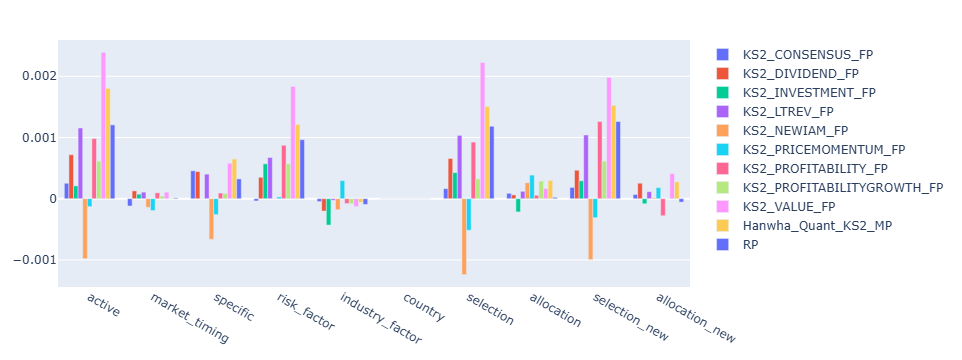

In [8]:
display(return_contribution_final.loc[plot_colums_list].style.format('{:.2%}'))

jh.tools.bar(return_contribution_final.loc[plot_colums_list])

### **항목별** 성과 기여도 추이

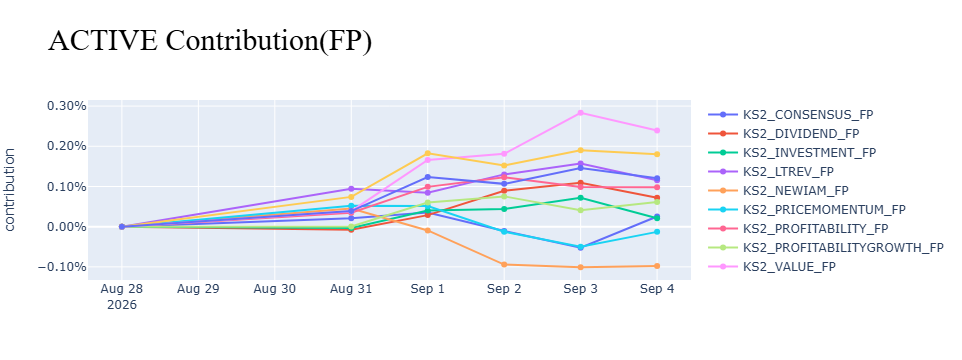

In [9]:
contribution_element = 'active' # 'active'/'market_timing'/'specific'/'country'/'risk_factor'/'industry_factor'/'beta'/'banks'..........
plot_data = compare_final.xs(contribution_element+'_contribution',level=1).copy()
plot_data_list = []
for _, port in enumerate(plot_data.columns):
    plot_data_list.append(go.Scatter(name=port, x=plot_data.index, y=plot_data[port], mode='lines+markers'))
fig = go.Figure(data=plot_data_list, layout={'yaxis':{'title':'contribution'}})
fig.update_layout(yaxis={'tickformat':'.2%'}, title=contribution_element.upper()+' Contribution(FP)', title_font_family="Times New Roman", title_font_color="black", title_font_size=30)
fig.show()

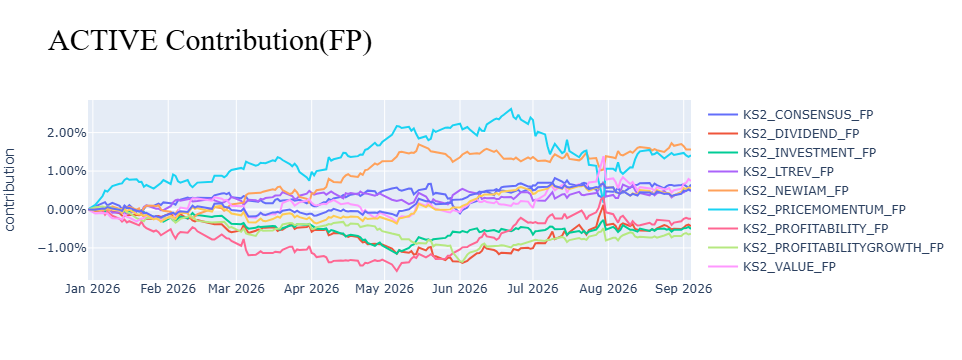

In [10]:
temp_start = '2025-12-30'
temp_mp_return_total = final_mp[['active_contribution_'+x for x in plot_data]].groupby(by='date').sum()
temp_mp_return_total.columns = temp_mp_return_total.columns.str.replace('active_contribution_','')
temp_mp_return_total = temp_mp_return_total.loc[temp_start:]
temp_mp_return_total = temp_mp_return_total.shift(1).fillna(0)
plot_data = (1+temp_mp_return_total).cumprod()-1

plot_data_list = []
for _, port in enumerate(plot_data.columns):
    plot_data_list.append(go.Scatter(name=port, x=plot_data.index, y=plot_data[port], mode='lines'))
fig = go.Figure(data=plot_data_list, layout={'yaxis':{'title':'contribution'}})
fig.update_layout(yaxis={'tickformat':'.2%'}, title=contribution_element.upper()+' Contribution(FP)', title_font_family="Times New Roman", title_font_color="black", title_font_size=30)
fig.show()

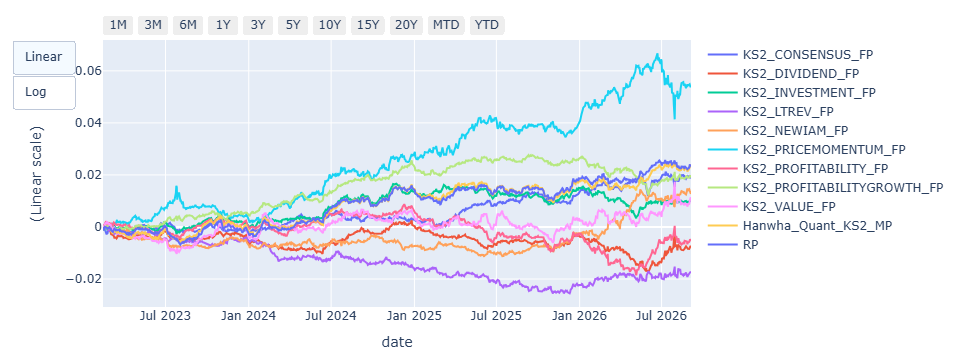

In [11]:
temp_mp_return_total = final_mp[['active_contribution_'+x for x in plot_data]].groupby(by='date').sum()
temp_mp_return_total.columns = temp_mp_return_total.columns.str.replace('active_contribution_','')
# temp_mp_return_total = temp_mp_return_total.loc[temp_start:]
temp_mp_return_total = temp_mp_return_total.shift(1).fillna(0)
plot_data = (1+temp_mp_return_total).cumprod()-1
jh.tools.plot(plot_data)

# plot_data_list = []
# for _, port in enumerate(plot_data.columns):
#     plot_data_list.append(go.Scatter(name=port, x=plot_data.index, y=plot_data[port], mode='lines+markers'))
# fig = go.Figure(data=plot_data_list, layout={'yaxis':{'title':'contribution'}})
# fig.update_layout(yaxis={'tickformat':'.2%'}, title=contribution_element.upper()+' Contribution(FP)', title_font_family="Times New Roman", title_font_color="black", title_font_size=30)
# fig.show()

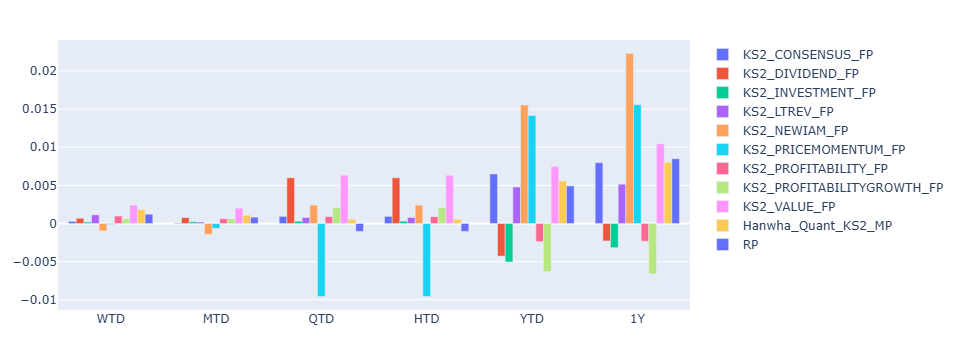

In [12]:
# mtd_date = '2023-10-31'
temp_mp_return_total = pd.DataFrame()
temp_mp_return_total['WTD'] = final_mp.loc[report_start_date:][['active_contribution_'+x for x in plot_data]].sum()
temp_mp_return_total['MTD'] = final_mp.loc[mtd_date:][['active_contribution_'+x for x in plot_data]].sum()
temp_mp_return_total['QTD'] = final_mp.loc[qtd_date:][['active_contribution_'+x for x in plot_data]].sum()
temp_mp_return_total['HTD'] = final_mp.loc[htd_date:][['active_contribution_'+x for x in plot_data]].sum()
temp_mp_return_total['YTD'] = final_mp.loc[ytd_date:][['active_contribution_'+x for x in plot_data]].sum()
temp_mp_return_total['1Y'] = final_mp.loc[y1_date:][['active_contribution_'+x for x in plot_data]].sum()
temp_mp_return_total.index = temp_mp_return_total.index.str.replace('active_contribution_','')
# jh.tools.plot((1+temp_mp_return_total.loc[temp_start:]).cumprod()-1)
jh.tools.bar(temp_mp_return_total.T)

### **항목별** 성과 기여도 **차이** 추이

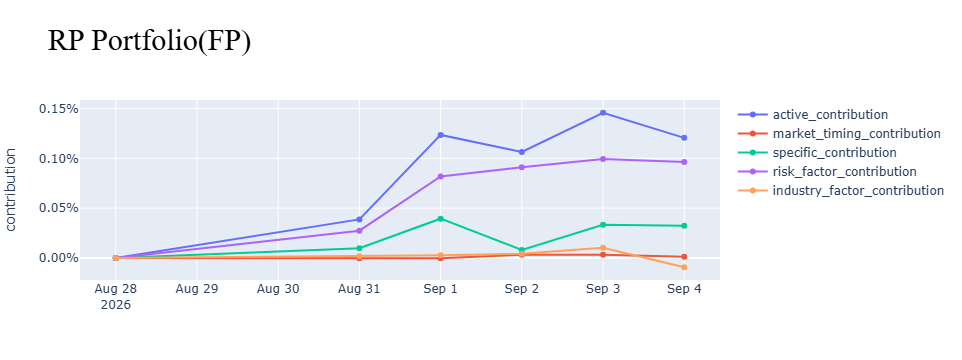

In [13]:
port_name = 'RP' #'KS2_CONSENSUS_FP', 'KS2_DIVIDEND_FP', 'KS2_INVESTMENT_FP','KS2_LTREV_FP', 'KS2_NEWIAM_FP', 'KS2_PRICEMOMENTUM_FP','KS2_PROFITABILITY_FP', 'KS2_PROFITABILITYGROWTH_FP', 'KS2_VALUE_FP','Hanwha_Quant_KS2_MP', 'RP'
idx = pd.IndexSlice
plot_data = compare_final.loc[idx[:,['active_contribution','market_timing_contribution','specific_contribution','risk_factor_contribution','industry_factor_contribution']],port_name].unstack()
plot_data_list = []
for _, element in enumerate(plot_data.columns):
    plot_data_list.append(go.Scatter(name=element, x=plot_data.index, y=plot_data[element], mode='lines+markers'))
fig = go.Figure(data=plot_data_list, layout={'yaxis':{'title':'contribution'}})
fig.update_layout(yaxis={'tickformat':'.2%'}, title=port_name.upper()+' Portfolio(FP)', title_font_family="Times New Roman", title_font_color="black", title_font_size=30)
fig.show()

### **MP별** 성과 기여도 추이

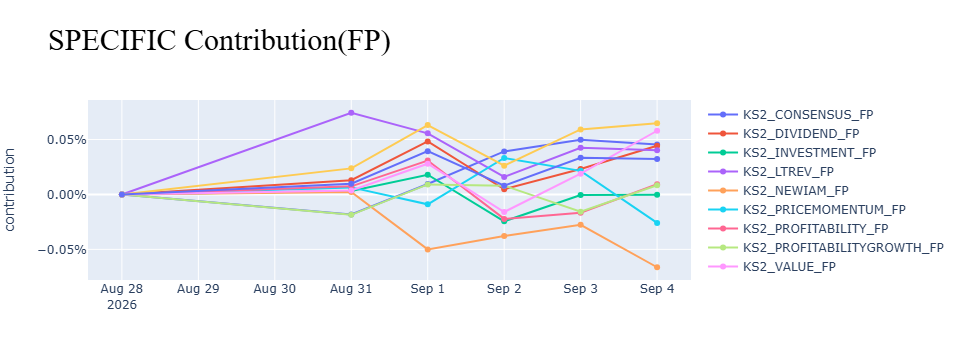

In [14]:
contribution_element = 'specific' # 'active'/'market_timing'/'specific'/'country'/'risk_factor'/'industry_factor'/'beta'/'banks'..........
plot_data = compare_final.xs(contribution_element+'_contribution',level=1).copy()
plot_data_list = []
for _, port in enumerate(plot_data.columns):
    plot_data_list.append(go.Scatter(name=port, x=plot_data.index, y=plot_data[port], mode='lines+markers'))
fig = go.Figure(data=plot_data_list, layout={'yaxis':{'title':'contribution'}})
fig.update_layout(yaxis={'tickformat':'.2%'}, title=contribution_element.upper()+' Contribution(FP)', title_font_family="Times New Roman", title_font_color="black", title_font_size=30)
fig.show()

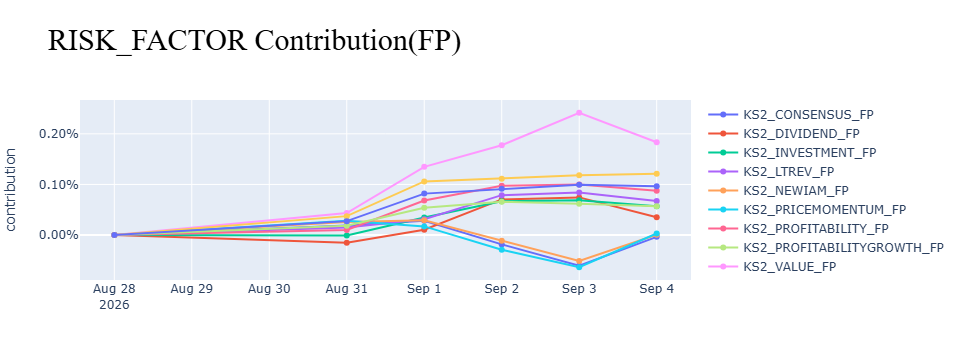

In [15]:
contribution_element = 'risk_factor' # 'active'/'market_timing'/'specific'/'country'/'risk_factor'/'industry_factor'/'beta'/'banks'..........
plot_data = compare_final.xs(contribution_element+'_contribution',level=1).copy()
plot_data_list = []
for _, port in enumerate(plot_data.columns):
    plot_data_list.append(go.Scatter(name=port, x=plot_data.index, y=plot_data[port], mode='lines+markers'))
fig = go.Figure(data=plot_data_list, layout={'yaxis':{'title':'contribution'}})
fig.update_layout(yaxis={'tickformat':'.2%'}, title=contribution_element.upper()+' Contribution(FP)', title_font_family="Times New Roman", title_font_color="black", title_font_size=30)
fig.show()

### **MP별** BPM Factor/Industry 성과 기여도 추이 (FP 기준)

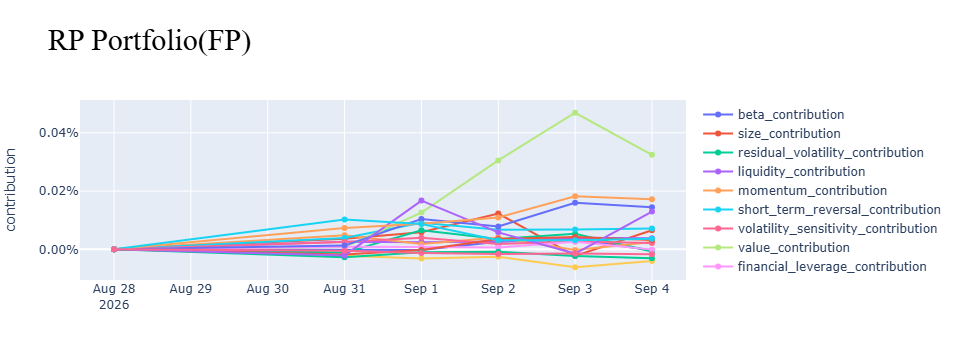

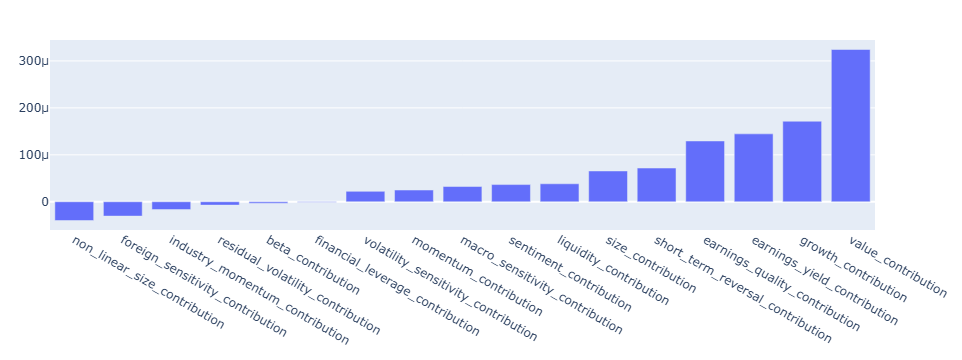

In [16]:
port_name = 'RP' # 'bpm'/'qnm'/'fcm'/'iam'/'imp'/'RP' / KS2_VALUE_FP
selected = 'risk_factor' # 'risk_factor'/'industry_factor'
# selected = 'industry_factor' # 'risk_factor'/'industry_factor'
idx = pd.IndexSlice
if selected=='risk_factor':
    plot_data = compare_final.loc[idx[:,[i+'_contribution' for i in list_bpm_factor]],port_name].unstack()
else:
    plot_data = compare_final.loc[idx[:,[i+'_contribution' for i in list_bpm_sector]],port_name].unstack()
plot_data_list = []
for _, element in enumerate(plot_data.columns):
    plot_data_list.append(go.Scatter(name=element, x=plot_data.index, y=plot_data[element], mode='lines+markers'))

fig = go.Figure(data=plot_data_list, layout={'yaxis':{'title':'contribution'}})
fig.update_layout(yaxis={'tickformat':'.2%'}, title=port_name.upper()+' Portfolio(FP)', title_font_family="Times New Roman", title_font_color="black", title_font_size=30)
fig.show()

jh.tools.bar(plot_data.iloc[-1,:].sort_values())

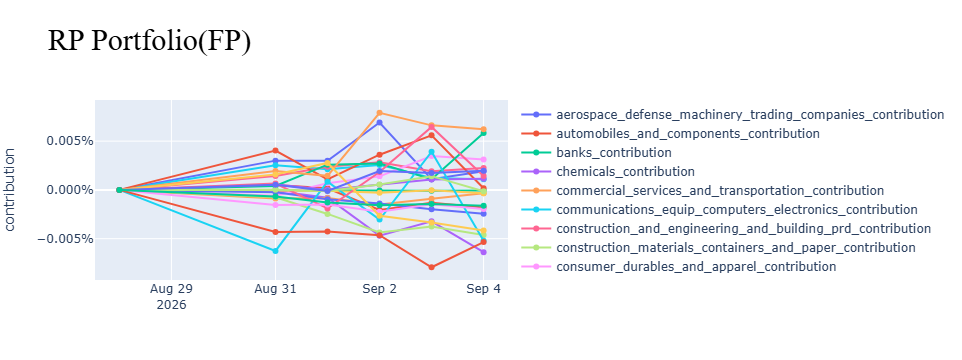

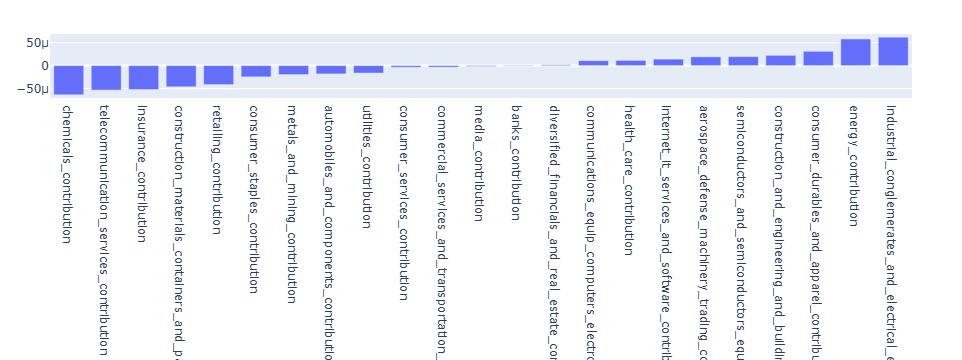

In [17]:
port_name = 'RP' # 'bpm'/'qnm'/'fcm'/'iam'/'imp'/'RP'
selected = 'industry_factor' # 'risk_factor'/'industry_factor'
# selected = 'industry_factor' # 'risk_factor'/'industry_factor'
idx = pd.IndexSlice
if selected=='risk_factor':
    plot_data = compare_final.loc[idx[:,[i+'_contribution' for i in list_bpm_factor]],port_name].unstack()
else:
    plot_data = compare_final.loc[idx[:,[i+'_contribution' for i in list_bpm_sector]],port_name].unstack()
plot_data_list = []
for _, element in enumerate(plot_data.columns):
    plot_data_list.append(go.Scatter(name=element, x=plot_data.index, y=plot_data[element], mode='lines+markers'))

fig = go.Figure(data=plot_data_list, layout={'yaxis':{'title':'contribution'}})
fig.update_layout(yaxis={'tickformat':'.3%'}, title=port_name.upper()+' Portfolio(FP)', title_font_family="Times New Roman", title_font_color="black", title_font_size=30)
fig.show()

jh.tools.bar(plot_data.iloc[-1,:].sort_values())

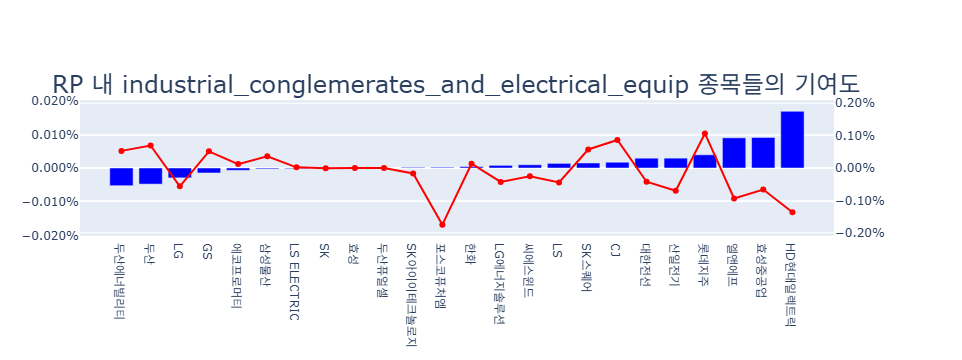

In [18]:
industry_name = 'industrial_conglemerates_and_electrical_equip' # industrial_conglemerates_and_electrical_equip (지주사/전기장비), communications_equip_computers_electronics
port_name = 'RP' # 'RP'

# sector_stock_list = sorted(set(final_mp.loc[(report_date_list,slice(None)),:][final_mp.loc[(report_date_list,slice(None)),'q_sector']==sector_name].index.get_level_values('item')))
indust_list_temp = final_mp.xs(mp_end_date).loc[final_mp.xs(mp_end_date)[industry_name]==1.0].index.to_list()
indust_list_temp = list(set(indust_list_temp) - set(['A001230']))
compare_contribution_final = pd.DataFrame(index=indust_list_temp, columns=return_contribution_final.columns)

for _,col in enumerate(compare_contribution_final.columns):
    compare_contribution_final.loc[indust_list_temp,col] = (final_mp.loc[(report_date_list,indust_list_temp),'active_contribution_'+col].\
                                                                                unstack().T*np.array(betalog_final.loc[:,col].shift(-1))).sum(axis=1)
compare_contribution_final = compare_contribution_final.join(info_stock).reset_index().set_index('name_stock')[return_contribution_final.columns].fillna(0.0)

spec_list = [list(np.repeat({'secondary_y':True},1))]
fig = make_subplots(rows=1, cols=1, subplot_titles=[port_name.upper()+' 내 '+industry_name+' 종목들의 기여도'], specs=spec_list)
plot_data = compare_contribution_final[[port_name]].rename(columns={port_name:port_name+'_contribution'})
plot_data = plot_data.join(final_mp.xs(mp_end_date).join(info_stock).reset_index().set_index('name_stock')[[port_name]]).fillna(0.0).rename(columns={port_name:port_name+'_active_weight'})

y1_min = -max([abs(plot_data[port_name+'_contribution'].min()),abs(plot_data[port_name+'_contribution'].max())])*1.2
y1_max = max([abs(plot_data[port_name+'_contribution'].min()),abs(plot_data[port_name+'_contribution'].max())])*1.2
y2_min = -max([abs(plot_data[port_name+'_active_weight'].min()),abs(plot_data[port_name+'_active_weight'].max())])*1.2
y2_max = max([abs(plot_data[port_name+'_active_weight'].min()),abs(plot_data[port_name+'_active_weight'].max())])*1.2
  
add_plot_data = plot_data.sort_values(port_name+'_contribution')

fig.add_trace(go.Bar(name=port_name+'_contribution', x=add_plot_data.index, y=add_plot_data[port_name+'_contribution'], marker={'color':'blue'}), row=1, col=1)
fig.add_trace(go.Scatter(name=port_name+'_active_weight', x=add_plot_data.index, y=add_plot_data[port_name+'_active_weight'], mode='lines+markers', marker={'color':'red'}), row=1, col=1, secondary_y=True)
fig.update_yaxes(tickformat='.3%', range=[y1_min, y1_max], secondary_y=False)
fig.update_yaxes(tickformat='.2%', range=[y2_min, y2_max], secondary_y=True)

fig.update_layout(height=350, showlegend=False)
fig.update_annotations({'font':{'size':24}})
fig.show()

### **업종별** Specific 기여도 추이

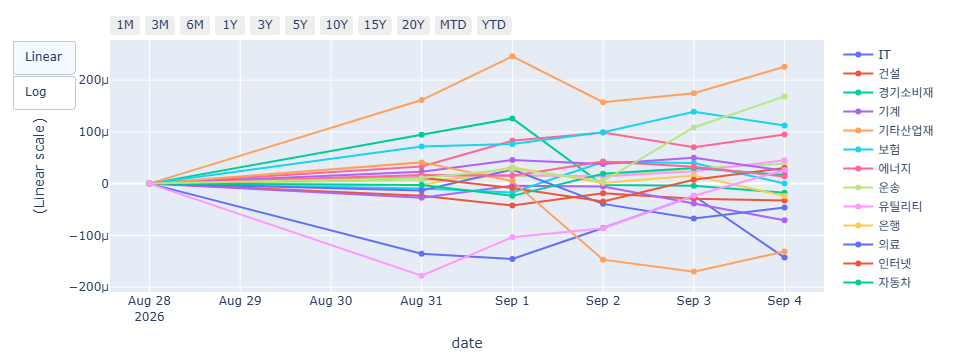

In [19]:
tmp_dt = final_mp[['specific_contribution_RP','q_sector']].reset_index().set_index('item')
tmp_dt['name'] = info_stock.loc[tmp_dt.index]['name_stock']
tmp_dt['q_sector'] = tmp_dt['q_sector'].astype('str')
tmp_dt = tmp_dt.reset_index().set_index(['date','item'])
tmp_dt = tmp_dt.dropna()
tmp_dt = tmp_dt.loc[report_start_date:]
# tmp_dt 'specific_contribution_RP', 'None'
# jh.tools.plot(tmp_dt.groupby(['date','q_sector']).sum().unstack())
jh.tools.plot(tmp_dt.groupby(['date','q_sector']).sum().unstack()['specific_contribution_RP'].cumsum().shift(1).fillna(0))

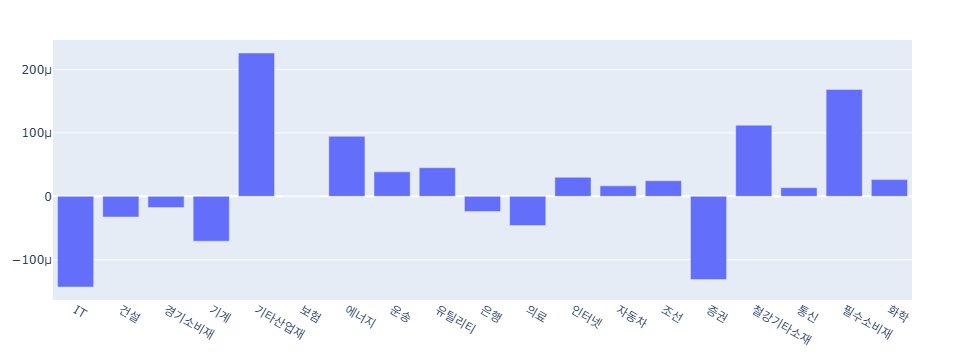

In [20]:
jh.tools.bar(tmp_dt.groupby(['date','q_sector']).sum().unstack()['specific_contribution_RP'].cumsum().loc[[mp_end_date]].T)
# jh.tools.bar(tmp_dt.groupby(['date','q_sector']).sum().unstack()['specific_contribution_RP'].cumsum().shift(1).loc[[mp_end_date]].T)

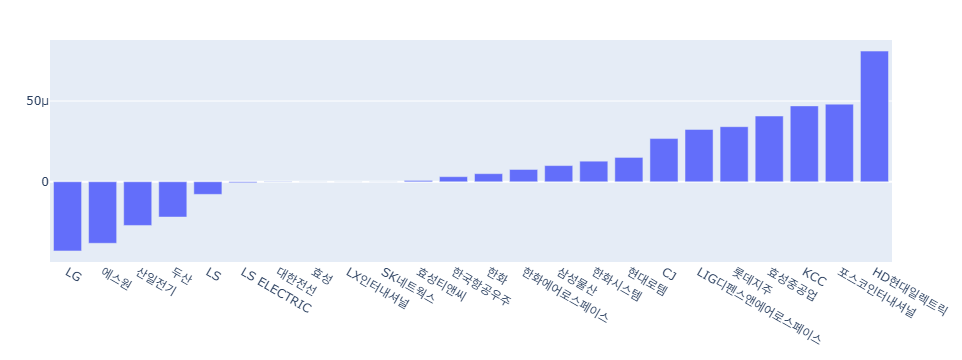

In [21]:
new_sector_name = '기타산업재' # 

tmp_dt = final_mp[['specific_contribution_RP']].reset_index().set_index(['date','item'])
tmp_dt = tmp_dt.loc[report_start_date:].groupby(level=1).sum()
tmp_dt['name'] = info_stock.loc[tmp_dt.index]['name_stock']
tmp_dt['q_sector'] = final_mp.xs(report_start_date)['q_sector'].astype('str')
tmp_dt = tmp_dt.loc[tmp_dt['q_sector']==new_sector_name].reset_index().set_index('name')[['specific_contribution_RP']].sort_values(by='specific_contribution_RP')
jh.tools.bar(tmp_dt)

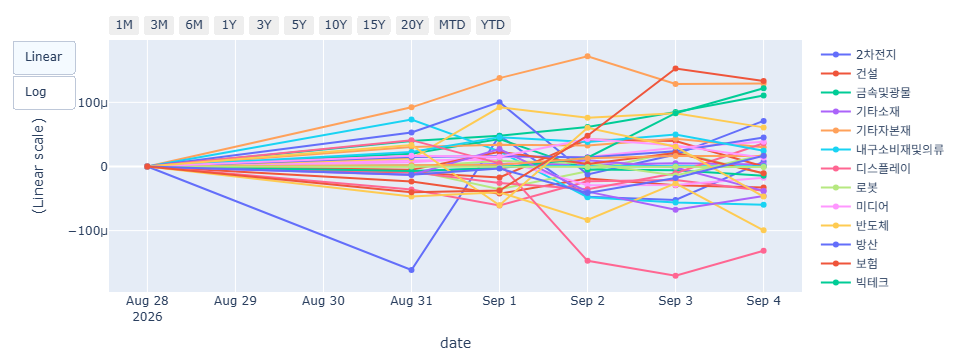

In [22]:
tmp_dt = final_mp[['specific_contribution_RP','new_sector']].reset_index().set_index('item')
tmp_dt['name'] = info_stock.loc[tmp_dt.index]['name_stock']
tmp_dt['new_sector'] = tmp_dt['new_sector'].astype('str')
tmp_dt = tmp_dt.reset_index().set_index(['date','item'])
tmp_dt = tmp_dt.dropna()
tmp_dt = tmp_dt.loc[report_start_date:]
# tmp_dt 'specific_contribution_RP', 'None'
# jh.tools.plot(tmp_dt.groupby(['date','q_sector']).sum().unstack())
jh.tools.plot(tmp_dt.groupby(['date','new_sector']).sum().unstack()['specific_contribution_RP'].cumsum().shift(1).fillna(0))

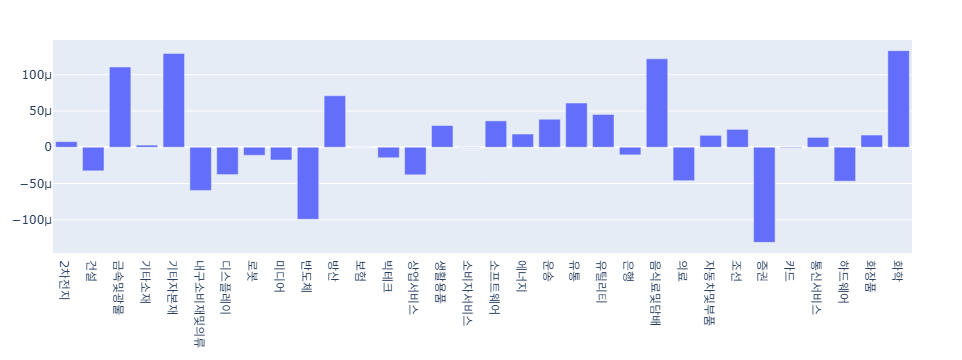

In [23]:
jh.tools.bar(tmp_dt.groupby(['date','new_sector']).sum().unstack()['specific_contribution_RP'].cumsum().loc[[mp_end_date]].T)
# jh.tools.bar(tmp_dt.groupby(['date','new_sector']).sum().unstack()['specific_contribution_RP'].cumsum().shift(1).loc[[mp_end_date]].T)

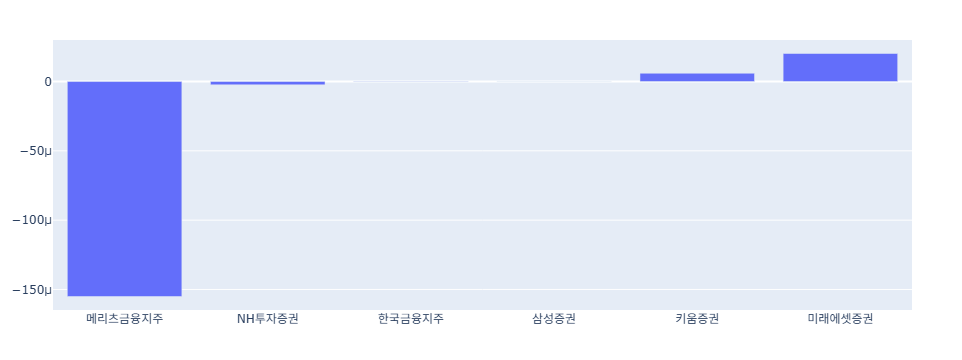

In [24]:
new_sector_name = '증권' # 2차전지, 방산

tmp_dt = final_mp[['specific_contribution_RP']].reset_index().set_index(['date','item'])
tmp_dt = tmp_dt.loc[report_start_date:].groupby(level=1).sum()
tmp_dt['name'] = info_stock.loc[tmp_dt.index]['name_stock']
tmp_dt['new_sector'] = final_mp.xs(report_start_date)['new_sector'].astype('str')
tmp_dt = tmp_dt.loc[tmp_dt['new_sector']==new_sector_name].reset_index().set_index('name')[['specific_contribution_RP']].sort_values(by='specific_contribution_RP')
jh.tools.bar(tmp_dt)

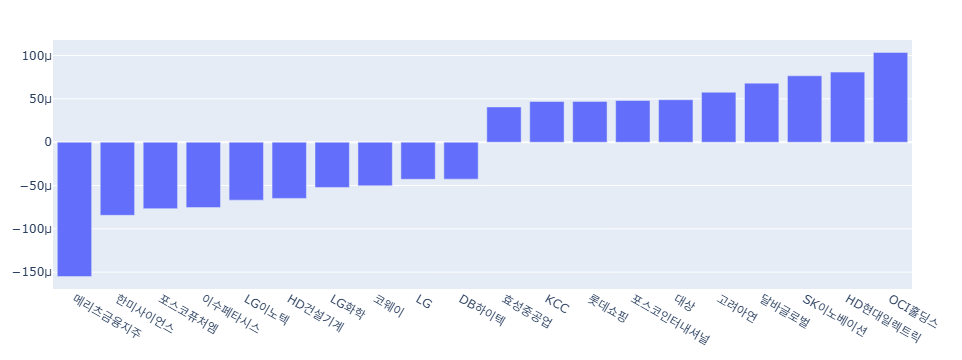

In [25]:
tmp_dt = final_mp[['specific_contribution_RP']].reset_index().set_index(['date','item'])
tmp_dt = tmp_dt.loc[report_start_date:].groupby(level=1).sum()
tmp_dt['name'] = info_stock.loc[tmp_dt.index]['name_stock']
tmp_dt = tmp_dt.set_index('name')[['specific_contribution_RP']].sort_values(by='specific_contribution_RP')
tmp_dt = pd.concat([tmp_dt.head(10),tmp_dt.tail(10)])
jh.tools.bar(tmp_dt)

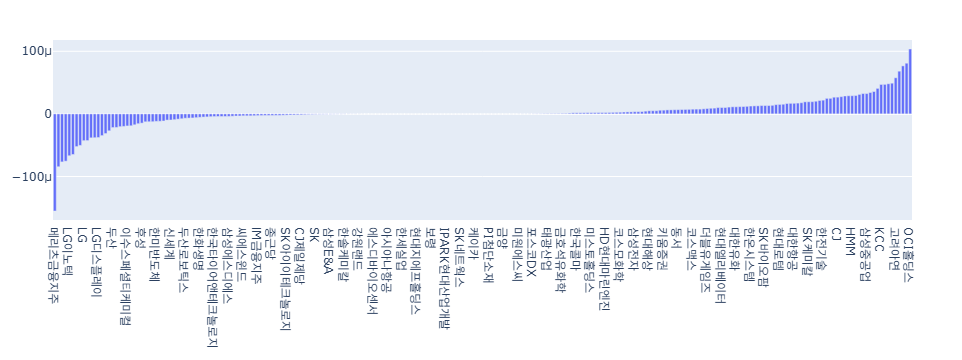

In [26]:
tmp_dt = final_mp[['specific_contribution_RP']]
tmp_dt = tmp_dt.reset_index().set_index(['date','item'])
tmp_dt = tmp_dt.dropna()
tmp_dt = tmp_dt.loc[report_start_date:].groupby(level=1).sum()
tmp_dt['name'] = info_stock.loc[tmp_dt.index]['name_stock']
tmp_dt = tmp_dt.set_index('name')[['specific_contribution_RP']].sort_values(by='specific_contribution_RP')
jh.tools.bar(tmp_dt)

### **종목별** 이익 기여도 Top/Bottom (FP 기준)

In [27]:
contribution_element = 'active' # 'active'/'market_timing'/'specific'/'country'/'risk_factor'/'industry_factor'/'beta'/'banks'..........
basis = 'fp' # 'pp'/'fp'

compare_contribution_final = pd.DataFrame(index=stock_list,columns=return_contribution_final.columns)

for _,col in enumerate(compare_contribution_final.columns):
    if contribution_element=='risk_factor':
        compare_contribution_final.loc[stock_list,col] = (final_mp.loc[(report_date_list,stock_list),[i+'_contribution_'+col for i in list_bpm_factor]].\
                                                                                    sum(axis=1).unstack().T*np.array(betalog_final.loc[:,col].shift(-1))).sum(axis=1)
    elif contribution_element=='industry_factor':
        compare_contribution_final.loc[stock_list,col] = (final_mp.loc[(report_date_list,stock_list),[i+'_contribution_'+col for i in list_bpm_sector]].\
                                                                                    sum(axis=1).unstack().T*np.array(betalog_final.loc[:,col].shift(-1))).sum(axis=1)
    else:
        compare_contribution_final.loc[stock_list,col] = (final_mp.loc[(report_date_list,stock_list),contribution_element+'_contribution_'+col].\
                                                                                    unstack().T*np.array(betalog_final.loc[:,col].shift(-1))).sum(axis=1)
compare_contribution_final = compare_contribution_final.join(info_stock).reset_index().set_index('name_stock')[return_contribution_final.columns].fillna(0.0)

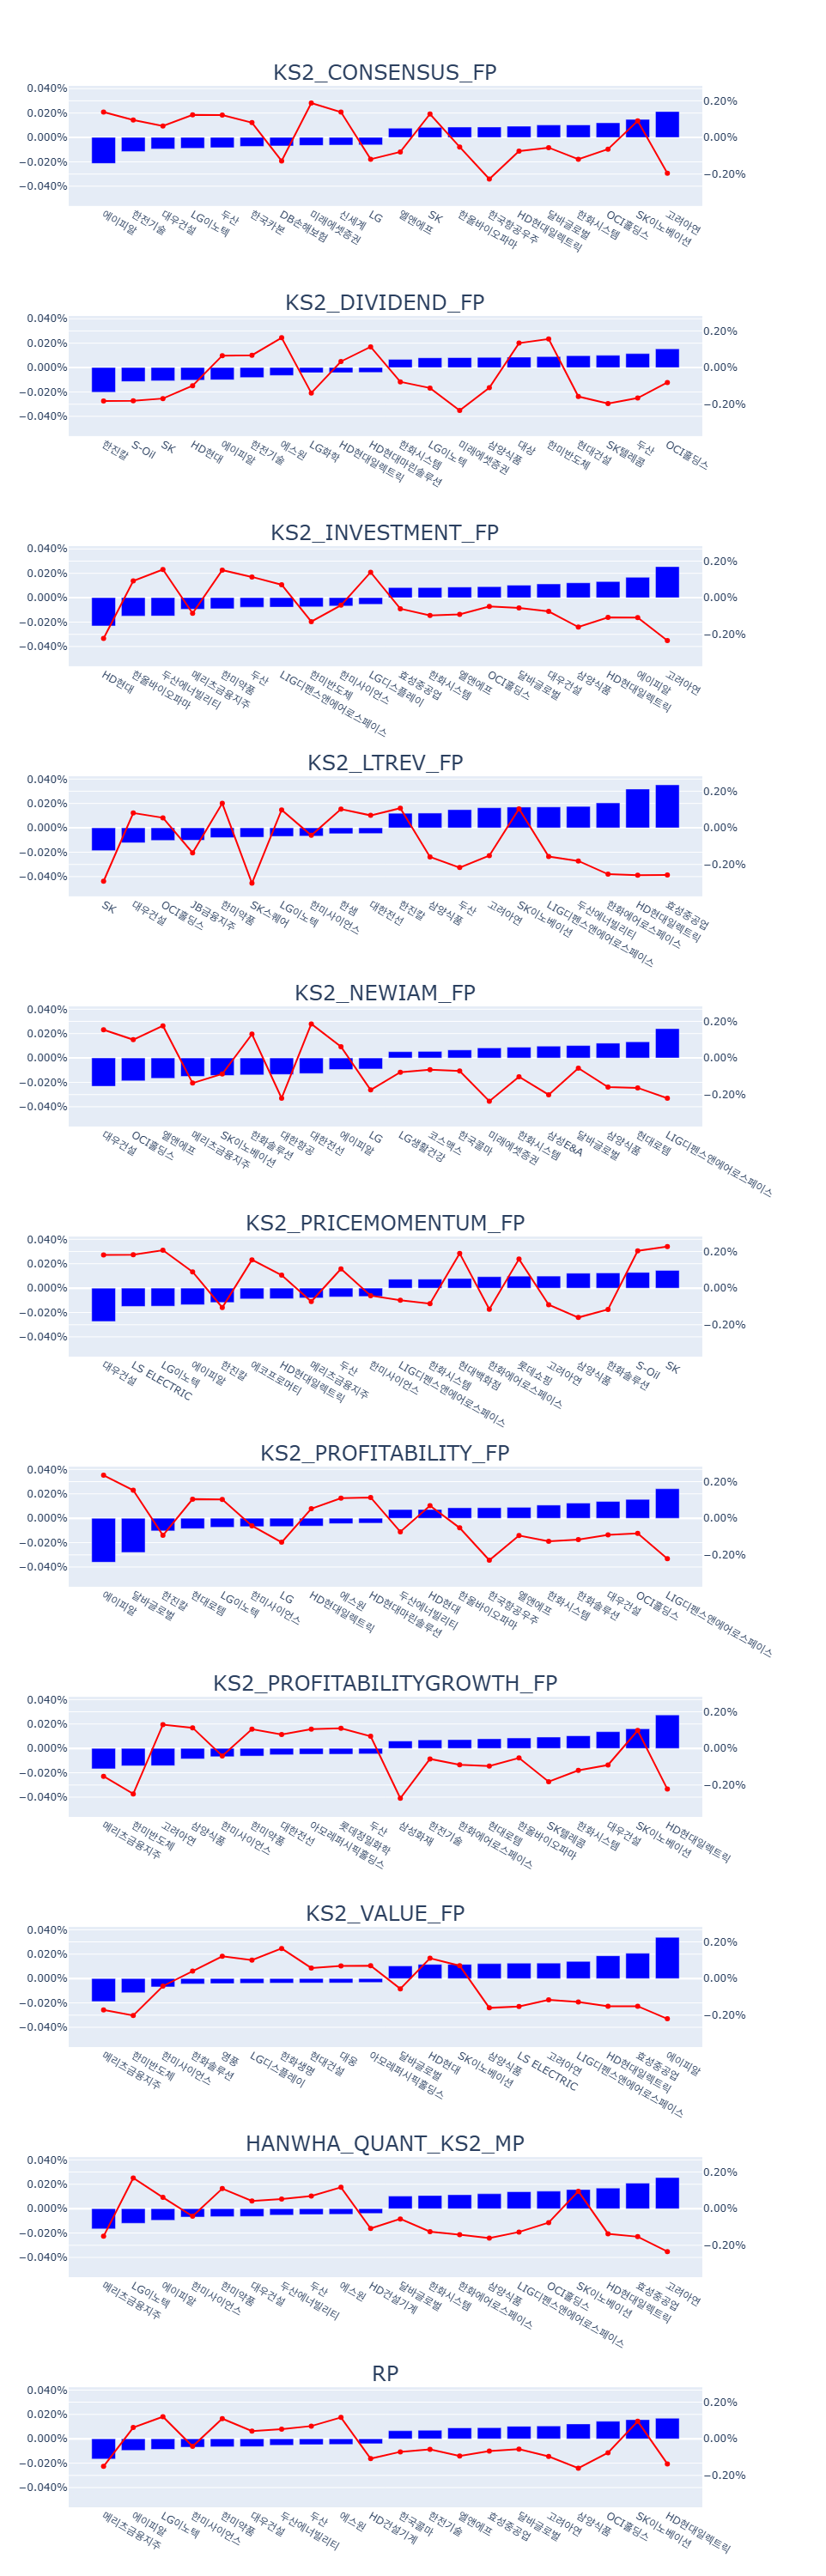

In [28]:
fig_rows = len(return_contribution_final.columns)
spec_list = [list(np.repeat({'secondary_y':True},1)) for i in range(fig_rows)]
fig = make_subplots(rows=fig_rows, cols=1, subplot_titles=[i.upper() for i in return_contribution_final.columns], specs=spec_list)
plot_data = compare_contribution_final[[i for i in return_contribution_final.columns]]
plot_data.columns = [i+'_contribution' for i in return_contribution_final.columns]
plot_data = plot_data.join(final_mp.xs(mp_end_date).join(info_stock).reset_index().set_index('name_stock')[[i for i in return_contribution_final.columns]]).fillna(0.0)
plot_data.columns = [i+'_contribution' for i in return_contribution_final.columns]+[i+'_active_weight' for i in plot_data.columns if i in return_contribution_final.columns]

y1_min = plot_data[[i for i in plot_data.columns if '_contribution' in i]].max().max()/plot_data[[i for i in plot_data.columns if '_active_weight' in i]].max().max()\
         *plot_data[[i for i in plot_data.columns if '_active_weight' in i]].min().min()*1.2
y1_max = plot_data[[i for i in plot_data.columns if '_contribution' in i]].max().max()*1.2
y2_min = plot_data[[i for i in plot_data.columns if '_active_weight' in i]].min().min()*1.2
y2_max = plot_data[[i for i in plot_data.columns if '_active_weight' in i]].max().max()*1.2

for i, port in enumerate(return_contribution_final.columns):
    if contribution_element in list_bpm_sector:
        bpm_sector_stock_list = final_mp.loc[(report_date_list,slice(None)),contribution_element].dropna().index.get_level_values('item').unique()
        add_plot_data = plot_data.loc[info_stock.loc[bpm_sector_stock_list,'name_stock'],:].sort_values(port+'_contribution')[[port+'_contribution',port+'_active_weight']]
    else:
        add_plot_data = plot_data.sort_values(port+'_contribution')[[port+'_contribution',port+'_active_weight']].iloc[np.r_[0:10, -10:0],:]
    fig.add_trace(go.Bar(name=port+'_contribution', x=add_plot_data.index, y=add_plot_data[port+'_contribution'], marker={'color':'blue'}), row=1+i, col=1)
    fig.add_trace(go.Scatter(name=port+'_active_weight', x=add_plot_data.index, y=add_plot_data[port+'_active_weight'], mode='lines+markers', marker={'color':'red'}), row=1+i, col=1, secondary_y=True)
    fig.update_yaxes(tickformat='.3%', range=[y1_min, y1_max], secondary_y=False)
    fig.update_yaxes(tickformat='.2%', range=[y2_min, y2_max], secondary_y=True)

fig.update_layout(height=3000, showlegend=False)
fig.update_annotations({'font':{'size':24}})
fig.show()

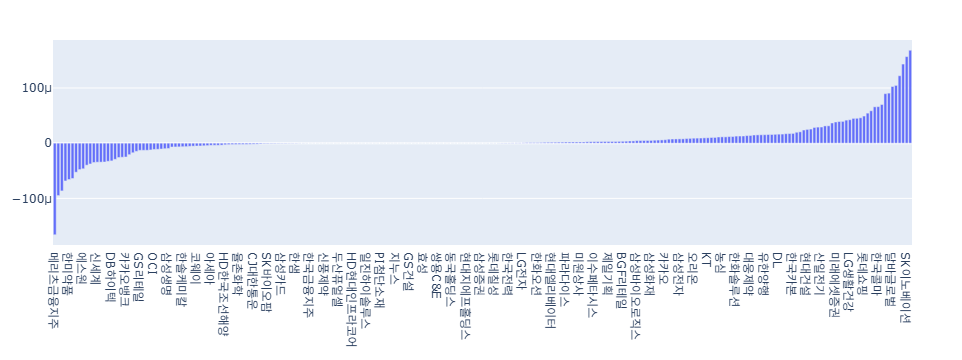

In [29]:
jh.tools.bar(plot_data.sort_values('RP_contribution')['RP_contribution'])

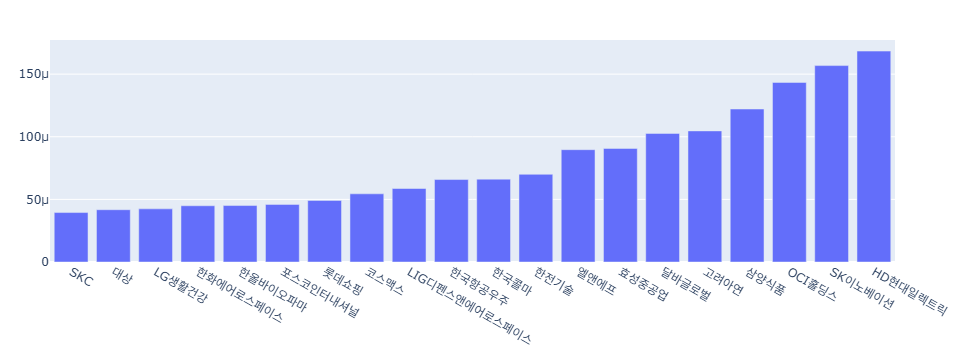

In [30]:
jh.tools.bar(plot_data.sort_values('RP_contribution').iloc[-20:]['RP_contribution'])

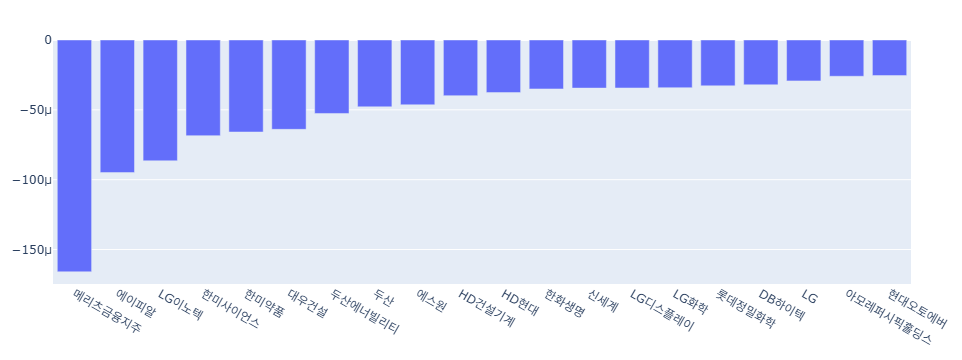

In [31]:
jh.tools.bar(plot_data.sort_values('RP_contribution').iloc[:20]['RP_contribution'])

### **업종별** Allocation / Selection 효과 (FP 기준)

,RP_selection,RP_allocation,RP
q_sector,,,
증권,-0.005%,-0.007%,-0.012%
기계,-0.006%,-0.000%,-0.007%
IT,-0.008%,0.003%,-0.005%
의료,-0.006%,0.001%,-0.005%
보험,-0.001%,-0.003%,-0.004%
건설,-0.003%,-0.001%,-0.003%
조선,-0.001%,0.000%,-0.000%
None,0.000%,0.000%,0.000%
은행,0.001%,-0.001%,0.000%


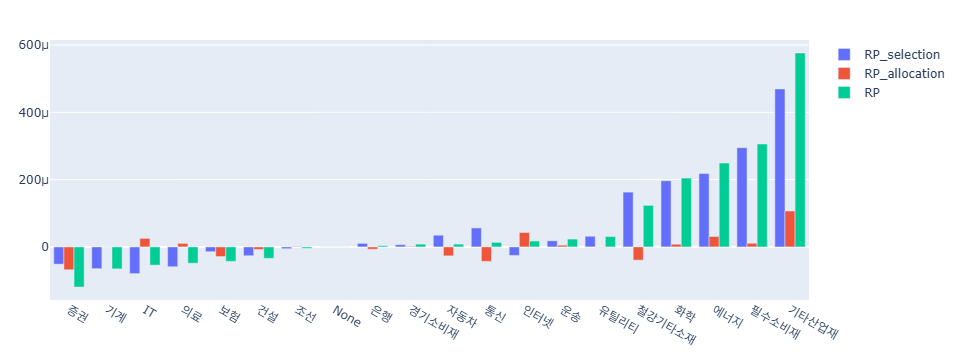

In [32]:
plot_data = sector_compare_final.dropna().copy()
for _, col in enumerate(return_contribution_final.columns):
    plot_data[col] = plot_data[col+'_allocation'] + plot_data[col+'_selection']

plot_data = plot_data.sort_values(by='RP')
display(plot_data[['RP_selection','RP_allocation','RP']].sort_values(by='RP').style.format('{:.3%}'))
jh.tools.bar(plot_data[['RP_selection','RP_allocation','RP']])

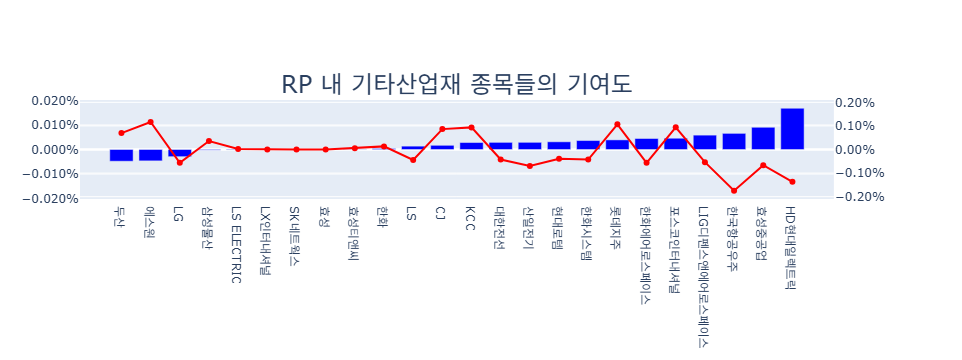

In [33]:
sector_name = '기타산업재' # 에너지, 기타산업재
port_name = 'RP' # 'RP','imp','bpm','qnm','iam','fcm'

sector_stock_list = sorted(set(final_mp.loc[(report_date_list,slice(None)),:][final_mp.loc[(report_date_list,slice(None)),'q_sector']==sector_name].index.get_level_values('item')))
sector_stock_list = list(set(sector_stock_list) - set(['A001230']))
compare_contribution_final = pd.DataFrame(index=sector_stock_list, columns=return_contribution_final.columns)

for _,col in enumerate(compare_contribution_final.columns):
    compare_contribution_final.loc[sector_stock_list,col] = (final_mp.loc[(report_date_list,sector_stock_list),'active_contribution_'+col].\
                                                                                unstack().T*np.array(betalog_final.loc[:,col].shift(-1))).sum(axis=1)
compare_contribution_final = compare_contribution_final.join(info_stock).reset_index().set_index('name_stock')[return_contribution_final.columns].fillna(0.0)

spec_list = [list(np.repeat({'secondary_y':True},1))]
fig = make_subplots(rows=1, cols=1, subplot_titles=[port_name.upper()+' 내 '+sector_name+' 종목들의 기여도'], specs=spec_list)
plot_data = compare_contribution_final[[port_name]].rename(columns={port_name:port_name+'_contribution'})
plot_data = plot_data.join(final_mp.xs(mp_end_date).join(info_stock).reset_index().set_index('name_stock')[[port_name]]).fillna(0.0).rename(columns={port_name:port_name+'_active_weight'})

y1_min = -max([abs(plot_data[port_name+'_contribution'].min()),abs(plot_data[port_name+'_contribution'].max())])*1.2
y1_max = max([abs(plot_data[port_name+'_contribution'].min()),abs(plot_data[port_name+'_contribution'].max())])*1.2
y2_min = -max([abs(plot_data[port_name+'_active_weight'].min()),abs(plot_data[port_name+'_active_weight'].max())])*1.2
y2_max = max([abs(plot_data[port_name+'_active_weight'].min()),abs(plot_data[port_name+'_active_weight'].max())])*1.2
  
add_plot_data = plot_data.sort_values(port_name+'_contribution')
fig.add_trace(go.Bar(name=port_name+'_contribution', x=add_plot_data.index, y=add_plot_data[port_name+'_contribution'], marker={'color':'blue'}), row=1, col=1)
fig.add_trace(go.Scatter(name=port_name+'_active_weight', x=add_plot_data.index, y=add_plot_data[port_name+'_active_weight'], mode='lines+markers', marker={'color':'red'}), row=1, col=1, secondary_y=True)
fig.update_yaxes(tickformat='.3%', range=[y1_min, y1_max], secondary_y=False)
fig.update_yaxes(tickformat='.2%', range=[y2_min, y2_max], secondary_y=True)

fig.update_layout(height=350, showlegend=False)
fig.update_annotations({'font':{'size':24}})
fig.show()

,RP_selection_new,RP_allocation_new,RP_contribution_new_sector
new_sector,,,
증권,-0.005%,-0.007%,-0.012%
하드웨어,-0.008%,-0.002%,-0.010%
의료,-0.006%,0.001%,-0.005%
상업서비스,0.000%,-0.005%,-0.005%
보험,-0.001%,-0.003%,-0.004%
디스플레이,-0.000%,-0.003%,-0.003%
건설,-0.003%,-0.001%,-0.003%
로봇,0.003%,-0.004%,-0.002%
내구소비재및의류,0.001%,-0.003%,-0.002%


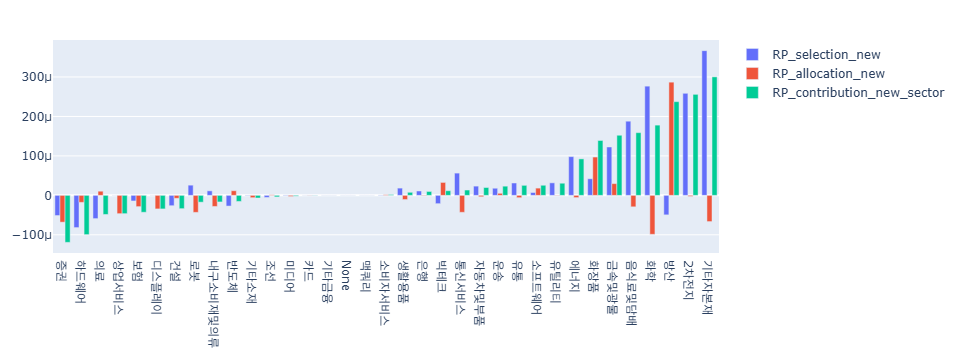

In [34]:
sector_compare_plot_data = new_sector_compare_final.copy()
sector_compare_plot_data['RP_contribution_new_sector'] = sector_compare_plot_data['RP_allocation_new'] + sector_compare_plot_data['RP_selection_new']
sector_compare_plot_data['RP_active_weight'] = final_mp.groupby('new_sector',group_keys=False)['RP'].sum()
sector_compare_plot_data = sector_compare_plot_data.sort_values('RP_contribution_new_sector')
display(sector_compare_plot_data[['RP_selection_new', 'RP_allocation_new','RP_contribution_new_sector']].style.format('{:.3%}'))
jh.tools.bar(sector_compare_plot_data[['RP_selection_new', 'RP_allocation_new','RP_contribution_new_sector']])

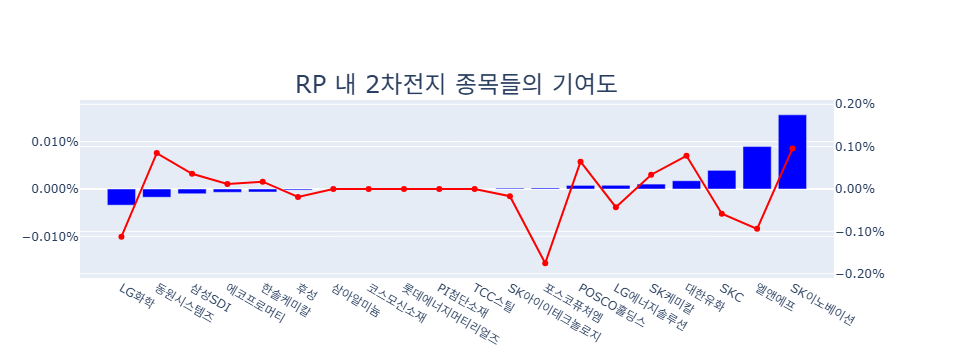

In [35]:
sector_name = '2차전지' # 방산
port_name = 'RP' # 'RP','imp','bpm','qnm','iam','fcm'

sector_stock_list = sorted(set(final_mp.loc[(report_date_list,slice(None)),:][final_mp.loc[(report_date_list,slice(None)),'new_sector']==sector_name].index.get_level_values('item')))
compare_contribution_final = pd.DataFrame(index=sector_stock_list, columns=return_contribution_final.columns)

for _,col in enumerate(compare_contribution_final.columns):
    compare_contribution_final.loc[sector_stock_list,col] = (final_mp.loc[(report_date_list,sector_stock_list),'active_contribution_'+col].\
                                                                                unstack().T*np.array(betalog_final.loc[:,col].shift(-1))).sum(axis=1)
compare_contribution_final = compare_contribution_final.join(info_stock).reset_index().set_index('name_stock')[return_contribution_final.columns].fillna(0.0)

spec_list = [list(np.repeat({'secondary_y':True},1))]
fig = make_subplots(rows=1, cols=1, subplot_titles=[port_name.upper()+' 내 '+sector_name+' 종목들의 기여도'], specs=spec_list)
plot_data = compare_contribution_final[[port_name]].rename(columns={port_name:port_name+'_contribution'})
plot_data = plot_data.join(final_mp.xs(mp_end_date).join(info_stock).reset_index().set_index('name_stock')[[port_name]]).fillna(0.0).rename(columns={port_name:port_name+'_active_weight'})

y1_min = -max([abs(plot_data[port_name+'_contribution'].min()),abs(plot_data[port_name+'_contribution'].max())])*1.2
y1_max = max([abs(plot_data[port_name+'_contribution'].min()),abs(plot_data[port_name+'_contribution'].max())])*1.2
y2_min = -max([abs(plot_data[port_name+'_active_weight'].min()),abs(plot_data[port_name+'_active_weight'].max())])*1.2
y2_max = max([abs(plot_data[port_name+'_active_weight'].min()),abs(plot_data[port_name+'_active_weight'].max())])*1.2

add_plot_data = plot_data.sort_values(port_name+'_contribution')
fig.add_trace(go.Bar(name=port_name+'_contribution', x=add_plot_data.index, y=add_plot_data[port_name+'_contribution'], marker={'color':'blue'}), row=1, col=1)
fig.add_trace(go.Scatter(name=port_name+'_active_weight', x=add_plot_data.index, y=add_plot_data[port_name+'_active_weight'], mode='lines+markers', marker={'color':'red'}), row=1, col=1, secondary_y=True)
fig.update_yaxes(tickformat='.3%', range=[y1_min, y1_max], secondary_y=False)
fig.update_yaxes(tickformat='.2%', range=[y2_min, y2_max], secondary_y=True)

fig.update_layout(height=350, showlegend=False)
fig.update_annotations({'font':{'size':24}})
fig.show()

### **Fund 성과 분석**
- 보유한 주식 및 선물, ETF, 우선주, 권리주 등을 보통주로 간주하여 계산
- 수정기준가 기준 Fund excess return = MP contribution + RP contribution + Manager contribution + Other contribution
- 주식으로 분해 한 포트폴리오의 excess return = MP contribution + RP contribution + Manager contribution
- Other contribution에 포함되는 효과 : 설정/환매 효과, 우선주/본주 괴리율, ETF 괴리율, 지수 및 개별주식 선물 효과, 배당 효과, 편입비 효과, 거래비용 등

In [36]:
# Fund Return Calculation
fund_code = '002840' # 수익률을 분석할 펀드 코드,  SJ: 002813(kospi200), YS: 117000(kospi200)/112012(kospi)/114732(kospi)/157010(kospi), EJ: 004250(kospi200)/105000(kospi200)/114932(kospi) 
fund_bm = 'kospi200_tr' # 펀드의 BM 'kospi'/'kospi200'/'nps'/'kospi_tr'
fund_analysis_start_date = report_start_date
fund_analysis_end_date = mp_end_date
bm_pre_rebal = False
if bm_pre_rebal:
    rebal_end_dt = '2026-06-08' # 마지막 리벨런싱일자(bm변경내역 반영할 mp 일자)
    bm_reb_date = '2026-06-12' # BM변경 반영일(effective date)

# 별도 설정 없으면 Hanwha_Quant_KSP_MP, Hanwha_Quant_KS2_RP 기본값
# EMP펀드 성과 확인을 위해 SMP 입력 필요
fund_mp_nm = '' # 114732_KSP_SMP / 114976_KSP_SMP

%run 'Function_fund_return_calculation_ver2.ipynb'

// Universe [None] is ready.
// Walking forward...


  0%            (DATE) 0/19 |                     Elapsed 00:00 | Remaining ? | ?s/it

// Testing is completed.

◎ Event Log
 ╭────────┬──────────────────────┬────────────┬────────────────────────────────╮
 │      1 │ Rebalancing          │ 2026-08-10 │ 200 trades                     │
 ╰────────┴──────────────────────┴────────────┴────────────────────────────────╯


date                       item   
2026-08-10 00:00:00+00:00  A000080    0.000715
                           A000100    0.000805
                           A000120    0.000765
                           A000150    0.003432
                           A000210    0.000385
                                        ...   
2026-09-04 00:00:00+00:00  A450080    0.000509
                           A454910    0.000032
                           A456040    0.000672
                           A457190    0.000021
                           A483650   -0.000012
Name: weight, Length: 3800, dtype: float64

// Universe [None] is ready.
// Walking forward...


  0%            (DATE) 0/19 |                     Elapsed 00:00 | Remaining ? | ?s/it

// Testing is completed.

◎ Event Log
 ╭────────┬──────────────────────┬────────────┬────────────────────────────────╮
 │      1 │ Rebalancing          │ 2026-08-10 │ 200 trades                     │
 ╰────────┴──────────────────────┴────────────┴────────────────────────────────╯


Copy Ratio(Fund vs. RP): 95.75%
-------------------------------------------
Copy Ratio(Fund vs. MP): 95.75%
-------------------------------------------
Copy Ratio(RP vs. MP): 100.00%


,total_return,bm_return,excess_return,mp_contribution,rp_contribution,manager_contribution,other_contribution
002840,-1.33%,-1.33%,0.00%,0.12%,0.00%,-0.11%,-0.01%


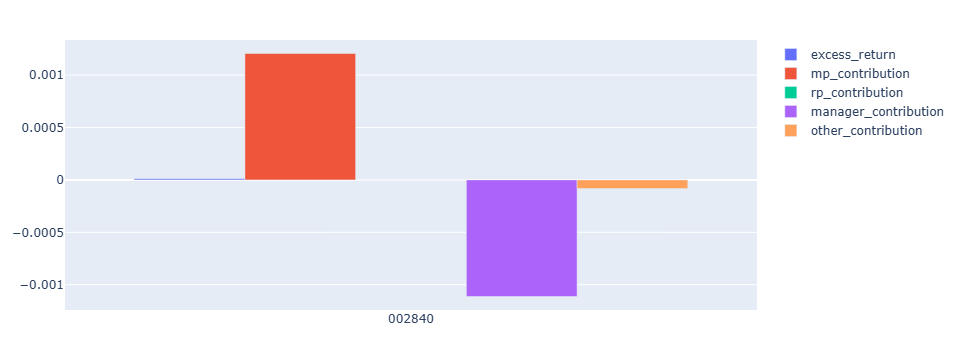

In [37]:
# Fund Return Summary Table
print('=================================================')
print('Copy Ratio(Fund vs. RP): {:2.2%}'.format(1-np.abs(weight_compare['fund']-weight_compare['rp']).sum()/2))
print('-------------------------------------------')
print('Copy Ratio(Fund vs. MP): {:2.2%}'.format(1-np.abs(weight_compare['fund']-weight_compare['mp']).sum()/2))
print('-------------------------------------------')
print('Copy Ratio(RP vs. MP): {:2.2%}'.format(1-np.abs(weight_compare['rp']-weight_compare['mp']).sum()/2))
print('=========================================================================================================')
if fund_bm_adj != fund_bm:
    display(fund_return_summary.drop(columns='bm_adj_return').style.format("{:.2%}"))
else:
    display(fund_return_summary.style.format("{:.2%}"))
jh.tools.bar(fund_return_summary[['excess_return','mp_contribution','rp_contribution','manager_contribution','other_contribution']])

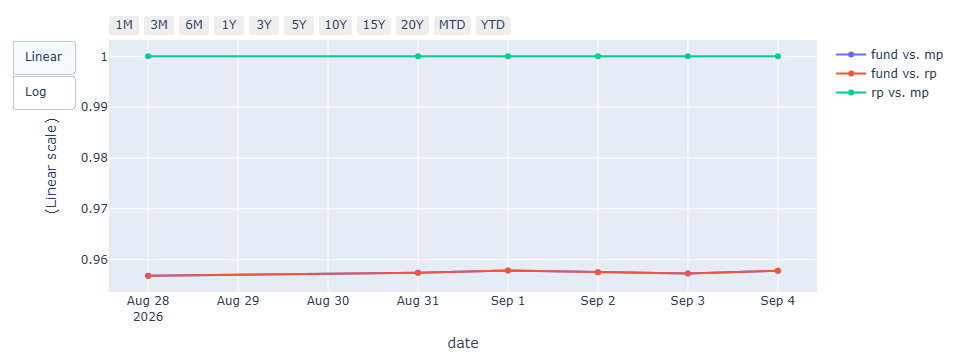

In [38]:
# Copy Ratio History
temp = stock_contribution['active_weight'].to_frame('fund')
temp = pd.concat([temp, mp_weights['weight'].to_frame('mp'), add_rp_weight['weight'].to_frame('rp')], axis=1)
temp.fillna(0, inplace=True)

temp_copy_ratio = pd.DataFrame()
temp_copy_ratio['fund vs. mp'] = temp.groupby('date')[['fund', 'mp']].apply(lambda x: 1-np.abs(x['fund']-x['mp']).sum()/2)
temp_copy_ratio['fund vs. rp'] = temp.groupby('date')[['fund', 'rp']].apply(lambda x: 1-np.abs(x['fund']-x['rp']).sum()/2)
temp_copy_ratio['rp vs. mp'] = temp.groupby('date')[['rp', 'mp']].apply(lambda x: 1-np.abs(x['rp']-x['mp']).sum()/2)
jh.tools.plot(temp_copy_ratio)

In [39]:
fund_return_time_series

,fund_return,bm_return,excess_return,mp_contribution,rp_contribution,manager_contribution,other_contribution
2026-08-28 00:00:00+00:00,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
2026-08-31 00:00:00+00:00,0.005322,0.005771,-0.000450,0.000387,0.0,-0.000301,-0.000536
2026-09-01 00:00:00+00:00,0.009014,0.009010,0.000004,0.001235,0.0,-0.001223,-0.000009
2026-09-02 00:00:00+00:00,-0.032237,-0.032060,-0.000177,0.001065,0.0,-0.000979,-0.000263
2026-09-03 00:00:00+00:00,-0.030977,-0.030850,-0.000127,0.001458,0.0,-0.001365,-0.000220
2026-09-04 00:00:00+00:00,-0.013293,-0.013303,0.000011,0.001206,0.0,-0.001113,-0.000083


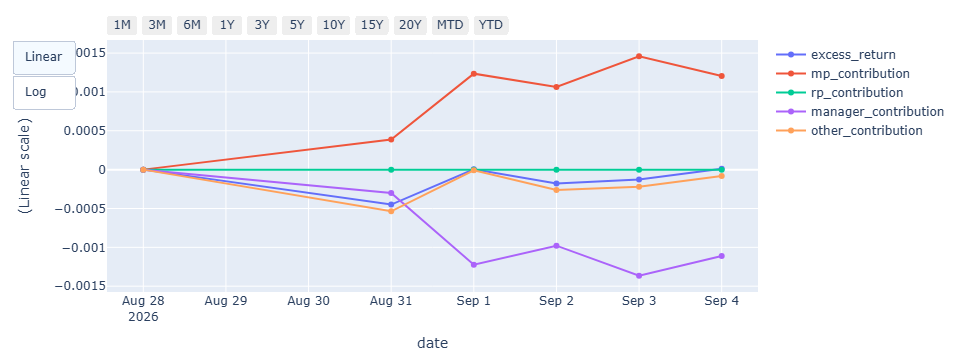

In [40]:
# 일별 Cumulative Return Contribution
jh.tools.plot(fund_return_time_series[[i for i in fund_return_time_series.columns if i not in ['fund_return','bm_return']]])
# jh.tools.plot(temp_return_time_series[[i for i in fund_return_time_series.columns if i not in ['fund_return','bm_return']]])

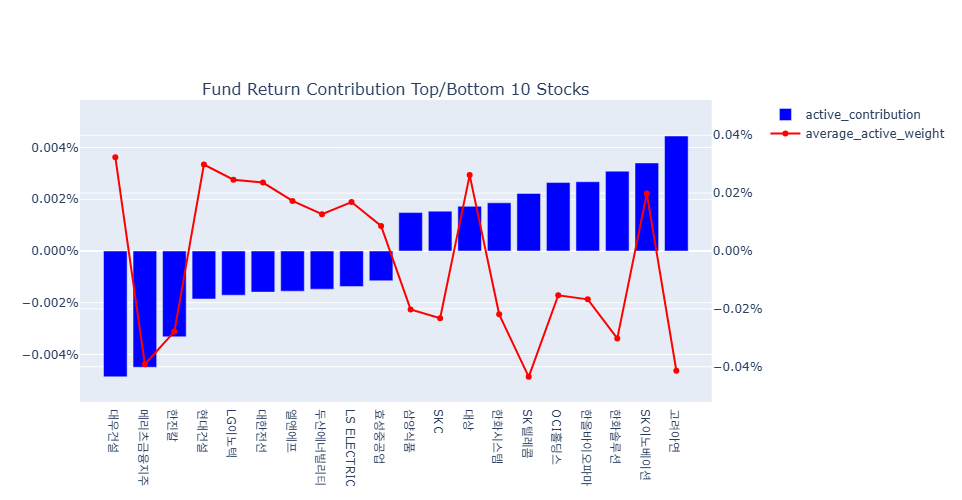

In [41]:
# Fund Return Contribution Top/Bottom 10 Stocks
spec_list = [list(np.repeat({'secondary_y':True},1))]
fig = make_subplots(rows=1, cols=1, subplot_titles=['Fund Return Contribution Top/Bottom 10 Stocks'], specs=spec_list)
plot_data = stock_contribution_compare[['active_contribution','average_active_weight']].sort_values('active_contribution').dropna().iloc[np.r_[0:10, -10:0],:]

y1_min = -max([abs(plot_data['active_contribution'].min()),abs(plot_data['active_contribution'].max())])*1.2
y1_max = max([abs(plot_data['active_contribution'].min()),abs(plot_data['active_contribution'].max())])*1.2
y2_min = -max([abs(plot_data['average_active_weight'].min()),abs(plot_data['average_active_weight'].max())])*1.2
y2_max = max([abs(plot_data['average_active_weight'].min()),abs(plot_data['average_active_weight'].max())])*1.2

fig.add_trace(go.Bar(name='active_contribution', x=plot_data.index, y=plot_data['active_contribution'], marker={'color':'blue'}), row=1, col=1)
fig.add_trace(go.Scatter(name='average_active_weight', x=plot_data.index, y=plot_data['average_active_weight'], mode='lines+markers', marker={'color':'red'}), row=1, col=1, secondary_y=True)
fig.update_yaxes(tickformat='.3%', range=[y1_min, y1_max], secondary_y=False)
fig.update_yaxes(tickformat='.2%', range=[y2_min, y2_max], secondary_y=True)
fig.update_layout(height=500, showlegend=True)

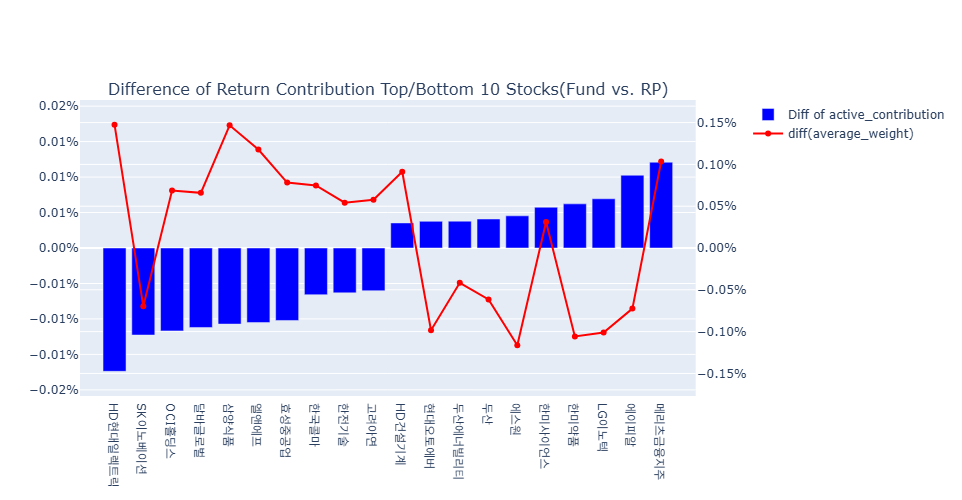

In [42]:
# 종목별 성과 기여도 차이(RP vs. Fund)
temp_sort = 'diff(return_contribution)' # diff(return_contribution) / diff(average_weight)
temp = stock_contribution_by_port.copy()[['name', 'fund', 'rp']]
temp['diff(return_contribution)'] = temp['fund'] - temp['rp']
temp['weight_fund'] = stock_contribution_compare.reset_index().set_index('item')['average_active_weight']
temp['weight_rp'] = add_rp_weight.fillna(0).groupby('item')['weight'].mean()
temp.fillna(0, inplace=True)
temp['diff(average_weight)'] = temp['weight_fund'] - temp['weight_rp']
temp = temp.reset_index().set_index('name')
temp.sort_values(by=temp_sort, ascending=True, inplace=True)
temp = pd.concat([temp.head(10),temp.tail(10)])
# temp = pd.concat([temp.head(10),temp.tail(10).iloc[:-1]])

fig = make_subplots(rows=1, cols=1, subplot_titles=['Difference of Return Contribution Top/Bottom 10 Stocks(Fund vs. RP)'], specs=spec_list)
y1_min = -max([abs(temp['diff(return_contribution)'].min()),abs(temp['diff(return_contribution)'].max())])*1.2
y1_max = max([abs(temp['diff(return_contribution)'].min()),abs(temp['diff(return_contribution)'].max())])*1.2
y2_min = -max([abs(temp['diff(average_weight)'].min()),abs(temp['diff(average_weight)'].max())])*1.2
y2_max = max([abs(temp['diff(average_weight)'].min()),abs(temp['diff(average_weight)'].max())])*1.2

fig.add_trace(go.Bar(name='Diff of active_contribution', x=temp.index, y=temp['diff(return_contribution)'], marker={'color':'blue'}), row=1, col=1)
fig.add_trace(go.Scatter(name='diff(average_weight)', x=temp.index, y=temp['diff(average_weight)'], mode='lines+markers', marker={'color':'red'}), row=1, col=1, secondary_y=True)
fig.update_yaxes(tickformat='.2%', range=[y1_min, y1_max], secondary_y=False)
fig.update_yaxes(tickformat='.2%', range=[y2_min, y2_max], secondary_y=True)
fig.update_layout(height=500, showlegend=True)

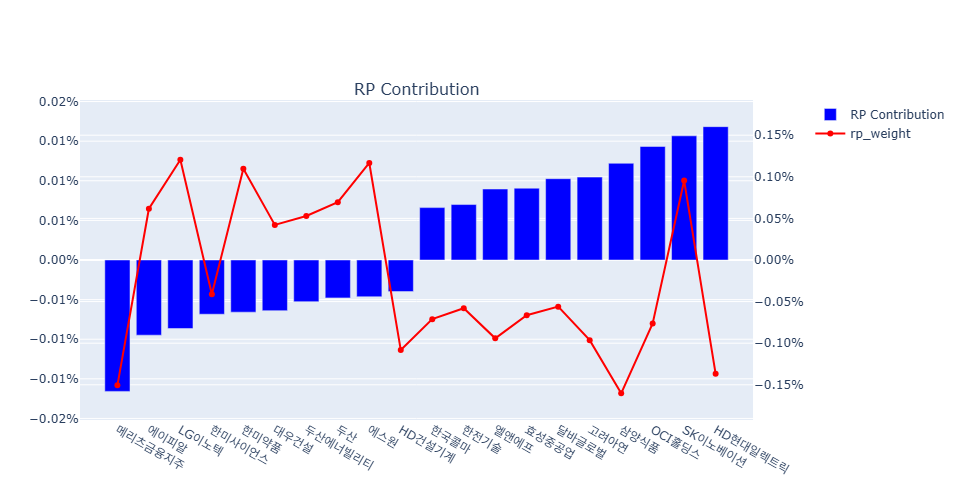

In [43]:
tmp = pd.DataFrame()
tmp['name'] = stock_contribution_by_port.sort_values(by='mp')['name']
tmp['mp_contribution'] = stock_contribution_by_port.sort_values(by='mp')['mp']
tmp['mp_weight'] = add_rp_weight.loc[fund_analysis_end_date]['weight']
tmp = pd.concat([tmp.head(10),tmp.tail(10)])

fig = make_subplots(rows=1, cols=1, subplot_titles=['RP Contribution'], specs=spec_list)
y1_min = -max([abs(tmp['mp_contribution'].min()),abs(tmp['mp_contribution'].max())])*1.2
y1_max = max([abs(tmp['mp_contribution'].min()),abs(tmp['mp_contribution'].max())])*1.2
y2_min = -max([abs(tmp['mp_weight'].min()),abs(tmp['mp_weight'].max())])*1.2
y2_max = max([abs(tmp['mp_weight'].min()),abs(tmp['mp_weight'].max())])*1.2

fig.add_trace(go.Bar(name='RP Contribution', x=tmp['name'], y=tmp['mp_contribution'], marker={'color':'blue'}), row=1, col=1)
fig.add_trace(go.Scatter(name='rp_weight', x=tmp['name'], y=tmp['mp_weight'], mode='lines+markers', marker={'color':'red'}), row=1, col=1, secondary_y=True)
fig.update_yaxes(tickformat='.2%', range=[y1_min, y1_max], secondary_y=False)
fig.update_yaxes(tickformat='.2%', range=[y2_min, y2_max], secondary_y=True)
fig.update_layout(height=500, showlegend=True)

Difference of active weights between fund and rp


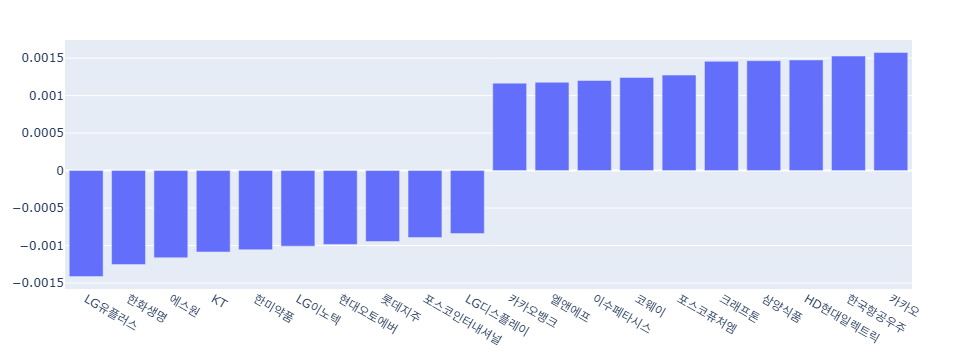

In [44]:
# 종목별 종목 비중 차이
temp_col_1 = 'fund'
temp_col_2 = 'rp'
temp = weight_compare[[temp_col_1, temp_col_2, 'name']]
temp['diff(weight)'] = temp[temp_col_1] - temp[temp_col_2]
print('Difference of active weights between',temp_col_1,'and',temp_col_2)
jh.tools.bar(temp.reset_index().set_index('name').sort_values(by='diff(weight)').iloc[np.r_[0:10, -10:0],:][['diff(weight)']])

fund기준 contribution 상위/하위 10 종목


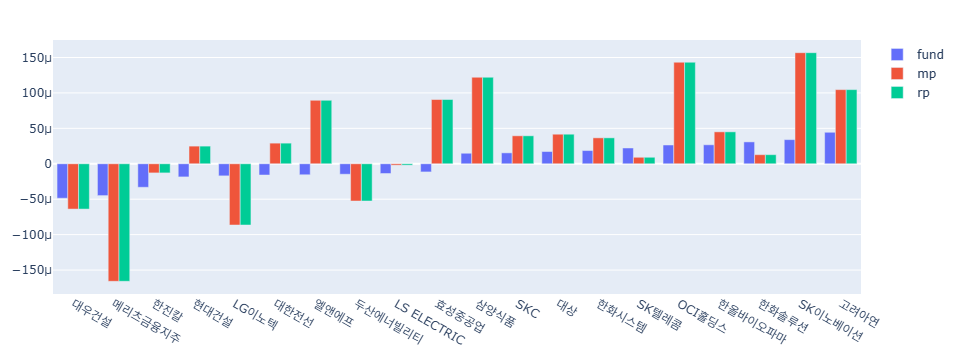

In [45]:
# 종목별 fund/mp/rp contribution 비교
sort_reference = 'fund' # 'fund'/'mp'/'rp' 기여도 정렬 기준
print(sort_reference+'기준 contribution 상위/하위 10 종목')
jh.tools.bar(stock_contribution_by_port.reset_index().set_index('name').sort_values(by=sort_reference).iloc[np.r_[0:10, -10:0],:][['fund','mp','rp']])

fund 기준 weight 상위/하위 10 종목


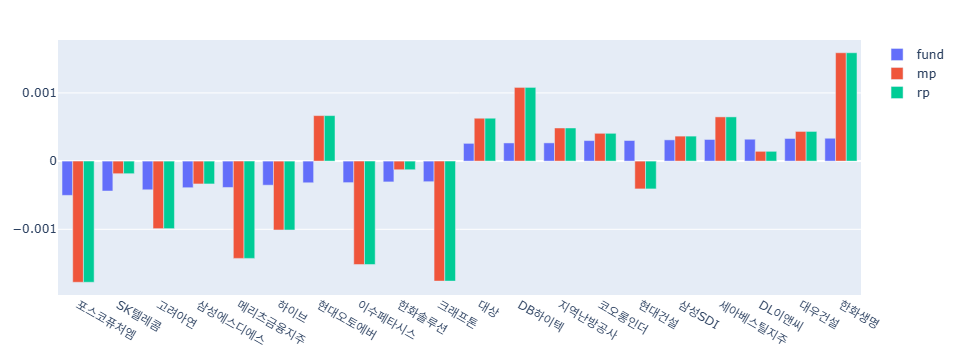

In [46]:
# 종목별 fund/mp/rp weight 비교
sort_reference = 'fund' # 'fund'/'mp'/'rp' 비중 정렬 기준
print(sort_reference+' 기준 weight 상위/하위 10 종목')
jh.tools.bar(weight_compare.reset_index().set_index('name').sort_values(by=sort_reference).iloc[np.r_[0:10, -10:0],:][['fund','mp','rp']])